# S&P 500 mode extraction

The initial results of posterior distribution of parameters for the MSSV model on S&P 500 data show 2 distinct modes. In this notebook we will try to effectively extract these modes and analyze their characteristics.

## Particle Gibbs results
First we analyze the results obtained from the Particle Gibbs sampling method. The multimodality is seen from parameters $\delta_2$, $\phi$ and $p_{22}$. Let's plot pairwise scatter plots of these parameters to visualize the modes.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import h5py
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from pathlib import Path

import os
import sys
import ast

# Add parent directory to sys.path
parent_dir = os.path.abspath(os.path.join(os.getcwd(), ".."))
sys.path.append(parent_dir)

from src.models.mssv import MSSVParams

In [2]:
def generate_names(n_params):
    """
    Generate dynamically parameter names based on the number of parameters. 
    First 1 is "mu1", next K-1 are "delta_i", next one is "phi", next one is "sigma^2" and then K*(K-1) flatten logits of transition matrix P.
    In total there is 1 + (K-1) + 1 + 1 + K*(K-1) = K*K + 2 parameters.
    """
    K = int(-1+np.sqrt(n_params+1))

    names = []
    names.append("mu1")
    for i in range(K-1):
        names.append(f"delta_{i+2}")  # delta_2, delta_3, ..., delta_K
    names.append("phi")
    names.append("sigma^2")
    for i in range(K):
        for j in range(K-1):
            names.append(f"logit_P_{i+1}_{j+1}")  # logit_P_1_1, logit_P_1_2, ..., logit_P_K_K

    return names

In [3]:
experiment_path = os.path.join(parent_dir, "experiments", "mssv_pg_sp500")
name = "sp500"

output_dir = os.path.join(experiment_path, name, "output")
results_dir = os.path.join(experiment_path, name, "results")
data_dir = os.path.join(parent_dir, "data", "real")

# Convert to pathlib.Path objects for easier path manipulation
output_dir = Path(output_dir)
results_dir = Path(results_dir)
data_dir = Path(data_dir)

In [4]:
# Get number of chain files from output_dir
chain_files = list(output_dir.glob("chain_*.h5"))
n_chains = len(chain_files)
print(f"Found {n_chains} chain files.")

# Dictionary to store chain data
chains_data = {}

for i in range(n_chains):
    print(f"Processing chain {i+1}/{n_chains}...")
    with h5py.File(output_dir / f"chain_{i}.h5", "r") as h5f:
        thetas = h5f["thetas"][:]
        logmarliks = h5f["logmarliks"][:]

        trajectories = h5f["trajectories"][:]

        chains_data[i] = {
            "thetas": thetas,
            "logmarliks": logmarliks,
            "trajectories": trajectories
        }

n_params = chains_data[0]["thetas"].shape[1]
T_plus_1 = chains_data[0]["trajectories"].shape[1]

Found 32 chain files.
Processing chain 1/32...
Processing chain 2/32...
Processing chain 3/32...
Processing chain 4/32...
Processing chain 5/32...
Processing chain 6/32...
Processing chain 7/32...
Processing chain 8/32...
Processing chain 9/32...
Processing chain 10/32...
Processing chain 11/32...
Processing chain 12/32...
Processing chain 13/32...
Processing chain 14/32...
Processing chain 15/32...
Processing chain 16/32...
Processing chain 17/32...
Processing chain 18/32...
Processing chain 19/32...
Processing chain 20/32...
Processing chain 21/32...
Processing chain 22/32...
Processing chain 23/32...
Processing chain 24/32...
Processing chain 25/32...
Processing chain 26/32...
Processing chain 27/32...
Processing chain 28/32...
Processing chain 29/32...
Processing chain 30/32...
Processing chain 31/32...
Processing chain 32/32...


In [5]:
thetas = []
logmarliks = []
for i in range(n_chains):
    logmarliks.extend(chains_data[i]["logmarliks"])
    for j in range(chains_data[i]["thetas"].shape[0]):
        n_params = chains_data[i]["thetas"].shape[1]
        K = int(-1+np.sqrt(n_params+1))
        theta = MSSVParams(
            mu1=chains_data[i]["thetas"][j, 0],
            delta=chains_data[i]["thetas"][j, 1:K],
            phi=chains_data[i]["thetas"][j, K],
            eta2=chains_data[i]["thetas"][j, K+1],
            P=chains_data[i]["thetas"][j, K+2:].reshape((K, K))
        )
        thetas.append(theta.to_unconstrained())
        
thetas = np.array(thetas)
logmarliks = np.array(logmarliks)

In [6]:
trajectories = []
for i in range(n_chains):
    for j in range(chains_data[i]["trajectories"].shape[0]):
        trajectories.append(chains_data[i]["trajectories"][j])

In [7]:
# Release memory
del chains_data

In [8]:
parameter_names = generate_names(n_params)
print("Parameter names:", parameter_names)

Parameter names: ['mu1', 'delta_2', 'phi', 'sigma^2', 'logit_P_1_1', 'logit_P_2_1']


In [9]:
print("Shape of thetas array:", thetas.shape)

Shape of thetas array: (320000, 6)


In [10]:
# Convert to pandas DataFrame for easier manipulation
df = pd.DataFrame(thetas, columns=parameter_names)
display(df.head())

,mu1,delta_2,phi,sigma^2,logit_P_1_1,logit_P_2_1
0,-9.884214,0.582501,1.795512,-3.010790,5.361514,-4.774963
1,-9.934070,0.280952,1.862852,-3.014600,5.896615,-4.571869
2,-10.053114,0.402594,1.938118,-3.032146,5.854442,-4.708134
3,-10.097121,0.523011,1.934931,-3.041191,5.734241,-4.776879
4,-10.004136,0.647722,1.896484,-3.042638,5.559482,-4.894591


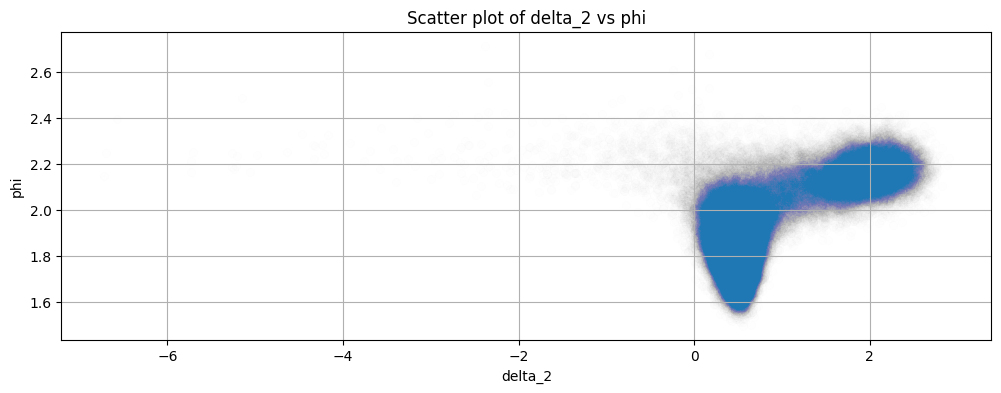

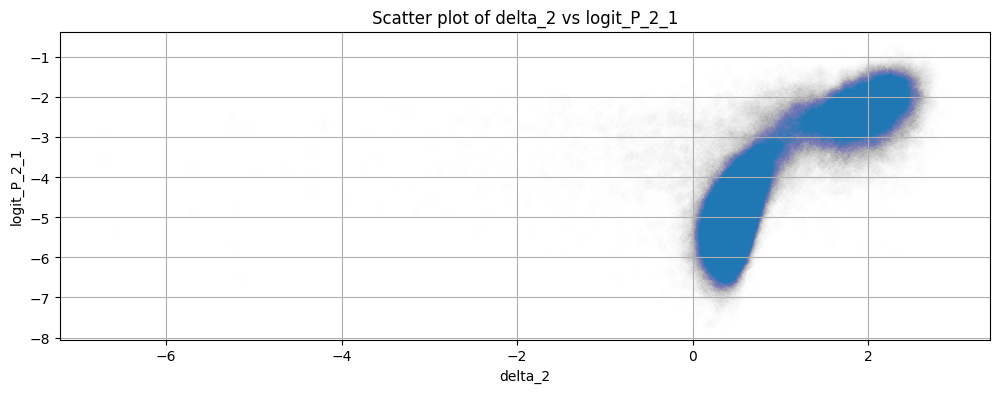

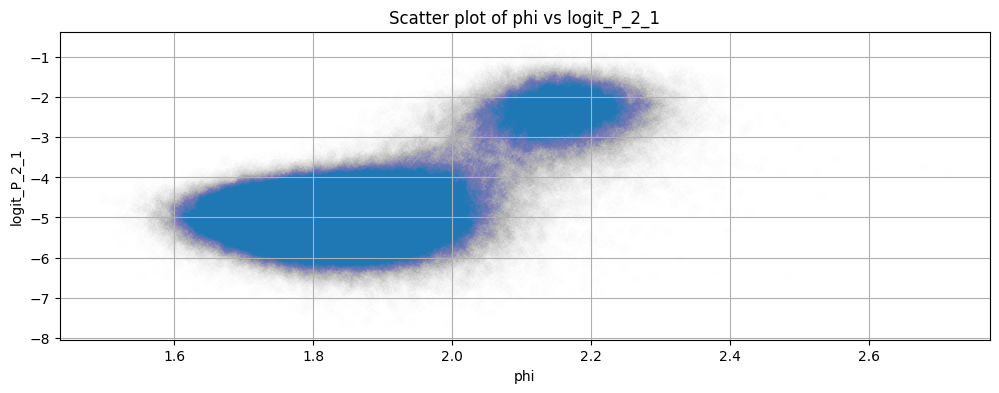

In [11]:
# delta_2, phi, and P_22 are at indices 1, K, and K*(K-1)+K+1 respectively in the unconstrained parameter vector. 

plt.figure(figsize=(12, 4))
plt.scatter(df["delta_2"], df["phi"], alpha=0.005)
plt.xlabel("delta_2")
plt.ylabel("phi")
plt.title("Scatter plot of delta_2 vs phi")
plt.grid()
plt.show()

plt.figure(figsize=(12, 4))
plt.scatter(df["delta_2"], df["logit_P_2_1"], alpha=0.005)
plt.xlabel("delta_2")
plt.ylabel("logit_P_2_1")
plt.title("Scatter plot of delta_2 vs logit_P_2_1")
plt.grid()
plt.show()

plt.figure(figsize=(12, 4))
plt.scatter(df["phi"], df["logit_P_2_1"], alpha=0.005)
plt.xlabel("phi")
plt.ylabel("logit_P_2_1")
plt.title("Scatter plot of phi vs logit_P_2_1")
plt.grid()
plt.show()

In [12]:
# Standardize the parameters for clustering using sklearn's StandardScaler
scaler = StandardScaler()
df_scaled = scaler.fit_transform(df)

In [13]:
# Perform KMeans clustering on the thetas using 2 clusters
kmeans = KMeans(n_clusters=2, random_state=42)
kmeans.fit(df_scaled)

# Add labels to the DataFrame
df['cluster'] = kmeans.labels_

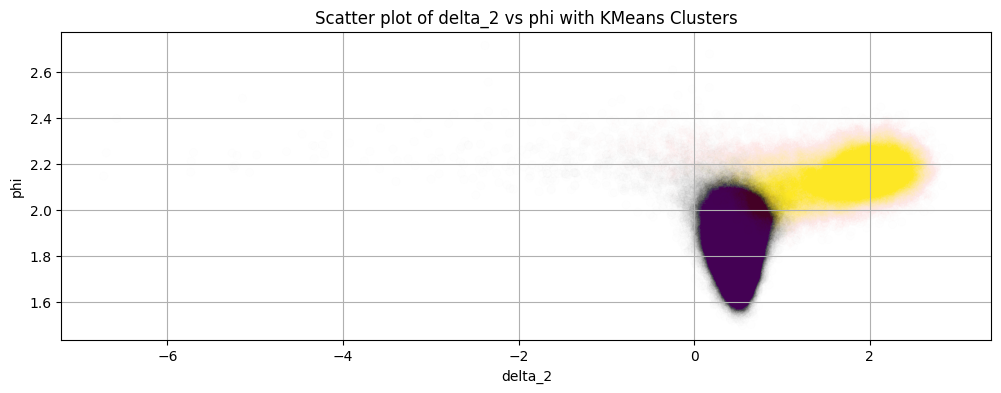

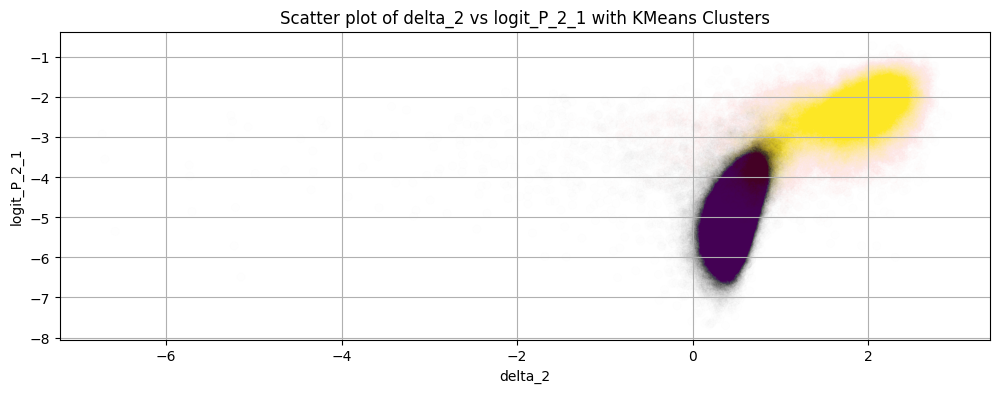

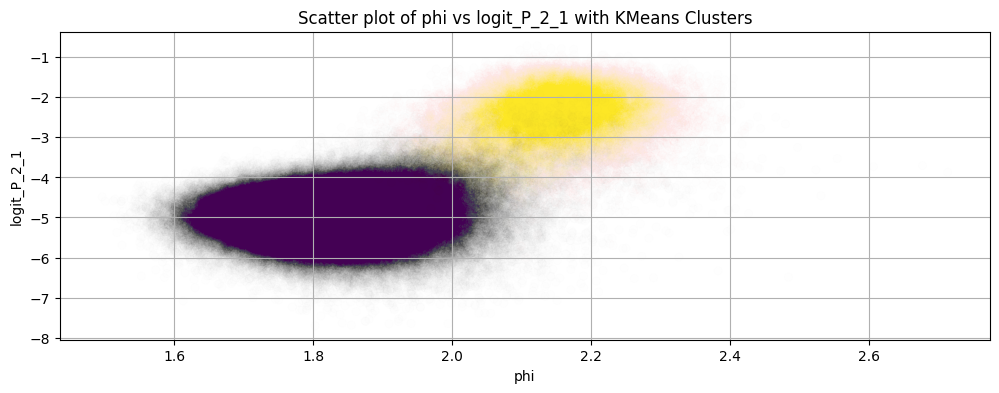

In [14]:
# Now you can visualize the clusters in the scatter plots
plt.figure(figsize=(12, 4))
plt.scatter(df["delta_2"], df["phi"], c=df['cluster'], cmap='viridis', alpha=0.005)
plt.xlabel("delta_2")
plt.ylabel("phi")
plt.title("Scatter plot of delta_2 vs phi with KMeans Clusters")
plt.grid(True)
plt.show()

plt.figure(figsize=(12, 4))
plt.scatter(df["delta_2"], df["logit_P_2_1"], c=df['cluster'], cmap='viridis', alpha=0.005)
plt.xlabel("delta_2")
plt.ylabel("logit_P_2_1")
plt.title("Scatter plot of delta_2 vs logit_P_2_1 with KMeans Clusters")
plt.grid(True)
plt.show()

plt.figure(figsize=(12, 4))
plt.scatter(df["phi"], df["logit_P_2_1"], c=df['cluster'], cmap='viridis', alpha=0.005)
plt.xlabel("phi")
plt.ylabel("logit_P_2_1")
plt.title("Scatter plot of phi vs logit_P_2_1 with KMeans Clusters")
plt.grid(True)
plt.show()


In [15]:
# Plot trajectories with "cluster" label 0
idx = df[df['cluster'] == 0].index

trajectories_cluster_0 = []
for i in idx:
    trajectories_cluster_0.append(trajectories[i])

In [16]:
print(f"Number of trajectories in cluster 0: {len(trajectories_cluster_0)}")

Number of trajectories in cluster 0: 285355


In [17]:
h_values = []
s_values = []
for traj in trajectories_cluster_0:
    h_values.append(traj[:, 0]) 
    s_values.append(traj[:, 1])

In [18]:
mean_h_values = np.empty((T_plus_1,))
mean_s_values = np.empty((T_plus_1,))
lower = np.empty(T_plus_1)
higher = np.empty(T_plus_1)

rng = np.random.default_rng(123)
subsampling_factor = 50  # Subsample factor to speed up computation
M = len(h_values)
idx = rng.choice(M, size=M // subsampling_factor, replace=False)

for t in range(T_plus_1):
    if t % 500 == 0:
        print(f"Processing time point {t}/{T_plus_1}...")
        
    column = [h_values[i][t] for i in idx]
    column = np.array(column)  # Convert to numpy array for mean and percentile calculations

    mean_h_values[t] = column.mean()
    lower[t], higher[t] = np.percentile(column, [2.5, 97.5])

    column_s = [s_values[i][t] for i in idx]
    column_s = np.array(column_s)  # Convert to numpy array for mean and percentile

    mean_s_values[t] = column_s.mean()

Processing time point 0/6664...
Processing time point 500/6664...
Processing time point 1000/6664...
Processing time point 1500/6664...
Processing time point 2000/6664...
Processing time point 2500/6664...
Processing time point 3000/6664...
Processing time point 3500/6664...
Processing time point 4000/6664...
Processing time point 4500/6664...
Processing time point 5000/6664...
Processing time point 5500/6664...
Processing time point 6000/6664...
Processing time point 6500/6664...


In [19]:
# Load the dates from real data
data = pd.read_csv(data_dir / "sp500" / "sp500.csv")
T = T_plus_1 - 1  # Exclude t=0 since it's the prior
# Keep only last T rows of data
data = data.tail(T)
dates = pd.to_datetime(data["Date"]).dt.date
dates = pd.to_datetime(dates).values

# Load the RV5 data
rv5_df = pd.read_csv(data_dir / "sp500" / "rv5_combined.csv")
rv5_values = rv5_df["RV5"].values
rv5_dates = pd.to_datetime(rv5_df["Date"]).dt.date
rv5_dates = pd.to_datetime(rv5_dates).values

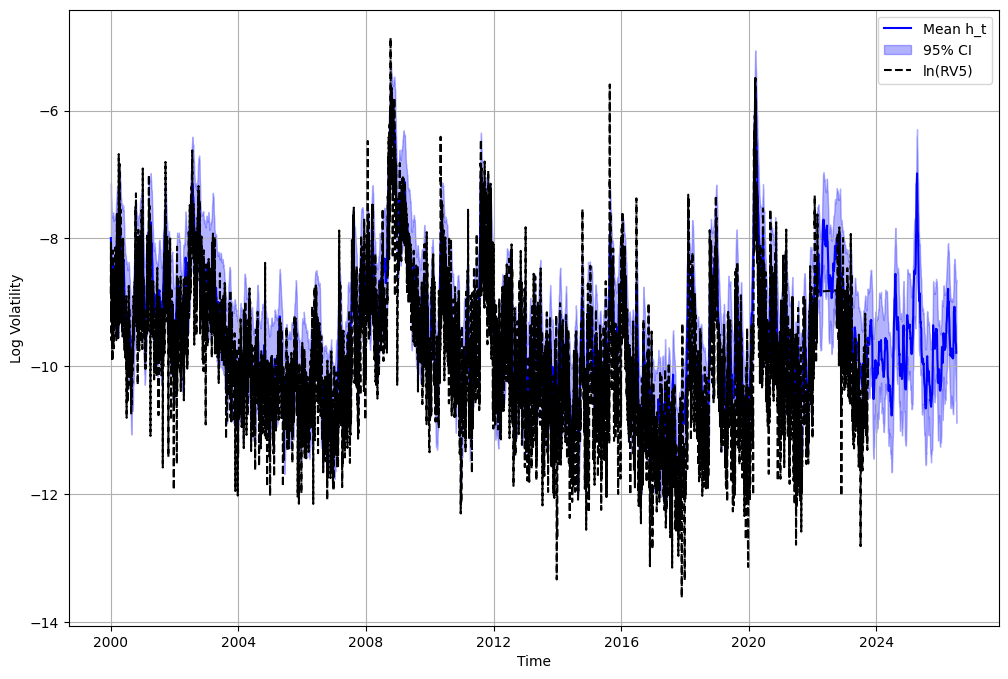

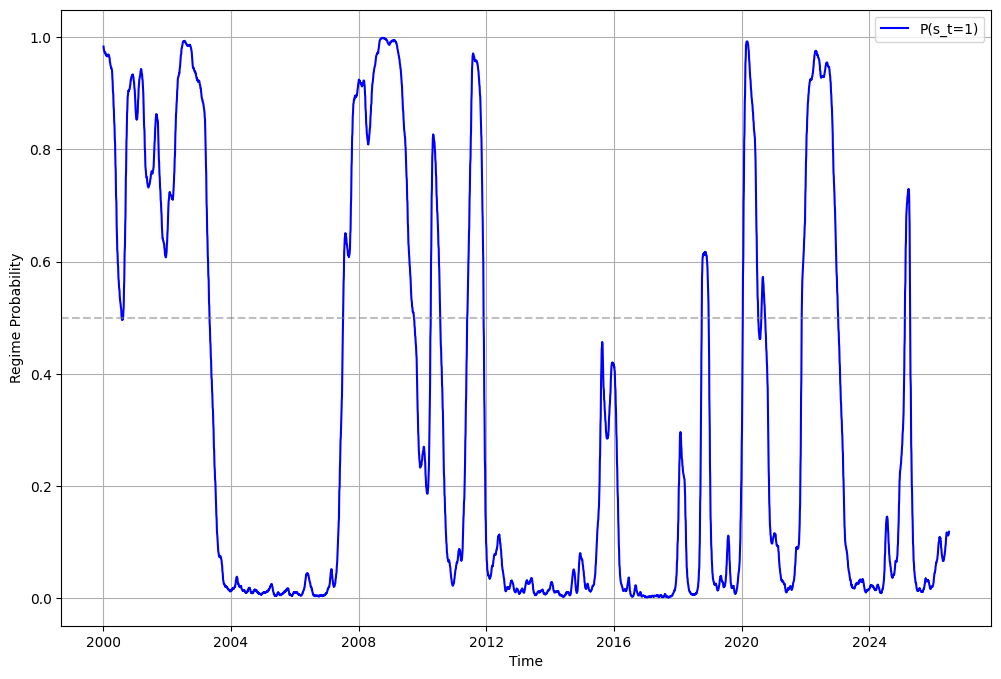

In [20]:
plt.figure(figsize=(12, 8))
plt.plot(dates, mean_h_values[1:], label="Mean h_t", color='blue')  
plt.fill_between(dates, lower[1:], higher[1:], color='blue', alpha=0.3, label="95% CI")
plt.plot(rv5_dates, np.log(rv5_values), label="ln(RV5)", color='black', linestyle='--')
plt.xlabel("Time")
plt.ylabel("Log Volatility")
plt.legend()
plt.grid()
plt.show()

plt.figure(figsize=(12, 8))
plt.plot(dates, mean_s_values[1:], label="P(s_t=1)", color='blue')
plt.axhline(0.5, color='grey', linestyle='--', alpha=0.5)
plt.xlabel("Time")
plt.ylabel("Regime Probability")
plt.legend()
plt.grid()
plt.show()

In [21]:
# Now repeat the same process for cluster 1
idx = df[df['cluster'] == 1].index

trajectories_cluster_1 = []
for i in idx:
    trajectories_cluster_1.append(trajectories[i])

In [22]:
print(f"Number of trajectories in cluster 1: {len(trajectories_cluster_1)}")

Number of trajectories in cluster 1: 34645


In [23]:
h_values = []
s_values = []
for traj in trajectories_cluster_1:
    h_values.append(traj[:, 0]) 
    s_values.append(traj[:, 1])

In [24]:
mean_h_values = np.empty((T_plus_1,))
mean_s_values = np.empty((T_plus_1,))
lower = np.empty(T_plus_1)
higher = np.empty(T_plus_1)

rng = np.random.default_rng(123)
subsampling_factor = 50  # Subsample factor to speed up computation
M = len(h_values)
idx = rng.choice(M, size=M // subsampling_factor, replace=False)

for t in range(T_plus_1):
    if t % 500 == 0:
        print(f"Processing time point {t}/{T_plus_1}...")
        
    column = [h_values[i][t] for i in idx]
    column = np.array(column)  # Convert to numpy array for mean and percentile calculations

    mean_h_values[t] = column.mean()
    lower[t], higher[t] = np.percentile(column, [2.5, 97.5])

    column_s = [s_values[i][t] for i in idx]
    column_s = np.array(column_s)  # Convert to numpy array for mean and percentile

    mean_s_values[t] = column_s.mean()

Processing time point 0/6664...
Processing time point 500/6664...
Processing time point 1000/6664...
Processing time point 1500/6664...
Processing time point 2000/6664...
Processing time point 2500/6664...
Processing time point 3000/6664...
Processing time point 3500/6664...
Processing time point 4000/6664...
Processing time point 4500/6664...
Processing time point 5000/6664...
Processing time point 5500/6664...
Processing time point 6000/6664...
Processing time point 6500/6664...


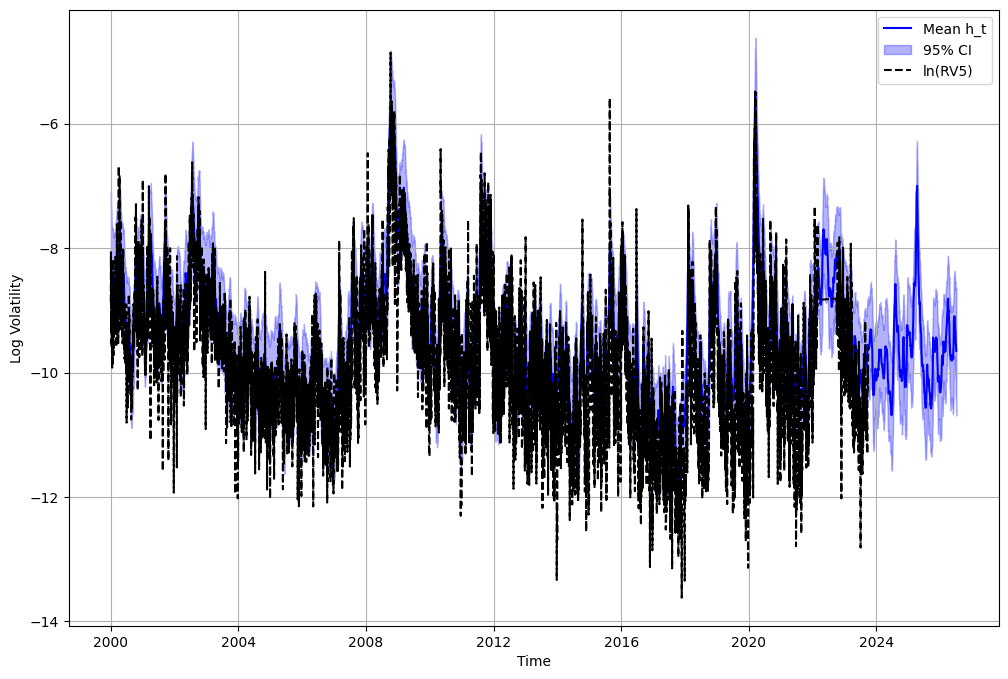

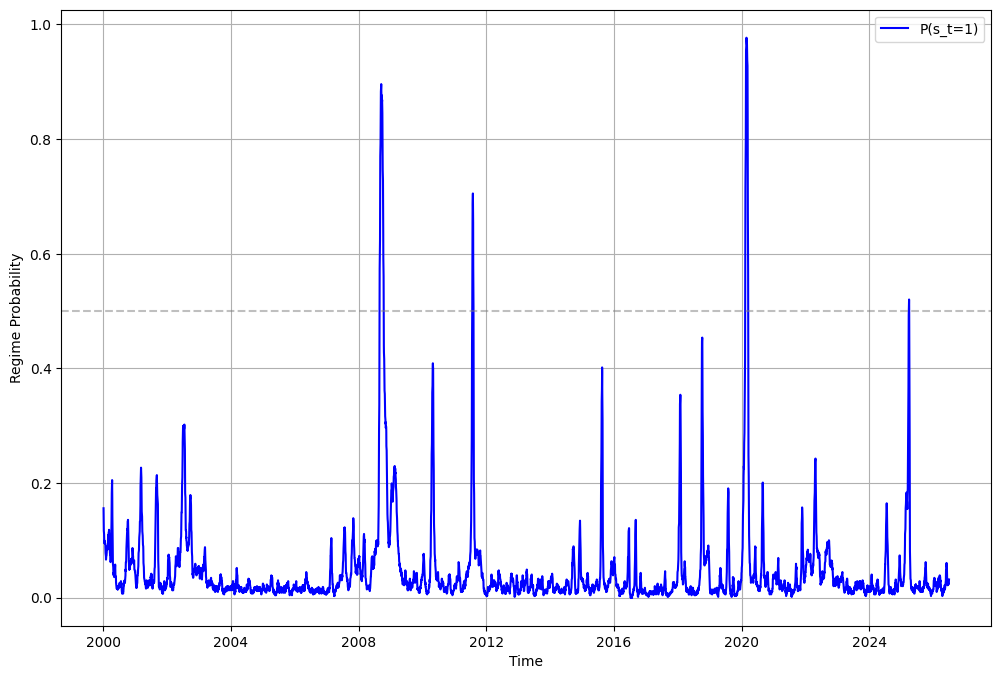

In [25]:
plt.figure(figsize=(12, 8))
plt.plot(dates, mean_h_values[1:], label="Mean h_t", color='blue')  
plt.fill_between(dates, lower[1:], higher[1:], color='blue', alpha=0.3, label="95% CI")
plt.plot(rv5_dates, np.log(rv5_values), label="ln(RV5)", color='black', linestyle='--')
plt.xlabel("Time")
plt.ylabel("Log Volatility")
plt.legend()
plt.grid()
plt.show()

plt.figure(figsize=(12, 8))
plt.plot(dates, mean_s_values[1:], label="P(s_t=1)", color='blue')
plt.axhline(0.5, color='grey', linestyle='--', alpha=0.5)
plt.xlabel("Time")
plt.ylabel("Regime Probability")
plt.legend()
plt.grid()
plt.show()

In [27]:
# Transform df parameters back to constrained space for easier interpretation
df_constrained = df.copy()
df_constrained["phi"] = df_constrained["phi"].apply(lambda x: np.tanh(x))  # Transform phi back to (-1, 1)
df_constrained["sigma^2"] = df_constrained["sigma^2"].apply(lambda x: np.exp(x))  # Transform sigma^2 back to positive values
df_constrained["P_1_1"] = df_constrained["logit_P_1_1"].apply(lambda x: 1 / (1 + np.exp(-x)))  # Transform logit_P_1_1 back to (0, 1)
df_constrained["P_1_2"] = 1 - df_constrained["P_1_1"]  # Since P_1_2 = 1 - P_1_1
df_constrained["P_2_1"] = df_constrained["logit_P_2_1"].apply(lambda x: 1 / (1 + np.exp(-x)))  # Transform logit_P_2_1 back to (0, 1)
df_constrained["P_2_2"] = 1 - df_constrained["P_2_1"]  # Since P_2_2 = 1 - P_2_1

# Drop other columns
df_constrained = df_constrained[["mu1", "delta_2", "phi", "sigma^2", "P_1_1", "P_1_2", "P_2_1", "P_2_2", "cluster"]]

In [31]:
# Print number of samples in each cluster
cluster_counts = df_constrained['cluster'].value_counts()
print("Number of samples in each cluster:")
print(cluster_counts)

Number of samples in each cluster:
cluster
0    285355
1     34645
Name: count, dtype: int64


Cluster 0 - mu1: Mean = -9.9695, 95% CI = [-10.1699, -9.7414]
Cluster 1 - mu1: Mean = -9.6626, 95% CI = [-9.9950, -9.4077]


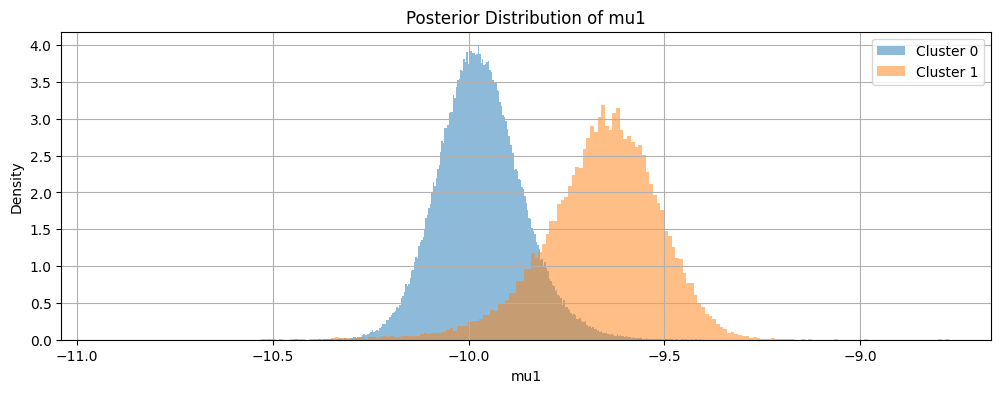

Cluster 0 - delta_2: Mean = 0.4681, 95% CI = [0.2129, 0.7014]
Cluster 1 - delta_2: Mean = 1.7243, 95% CI = [0.5630, 2.4891]


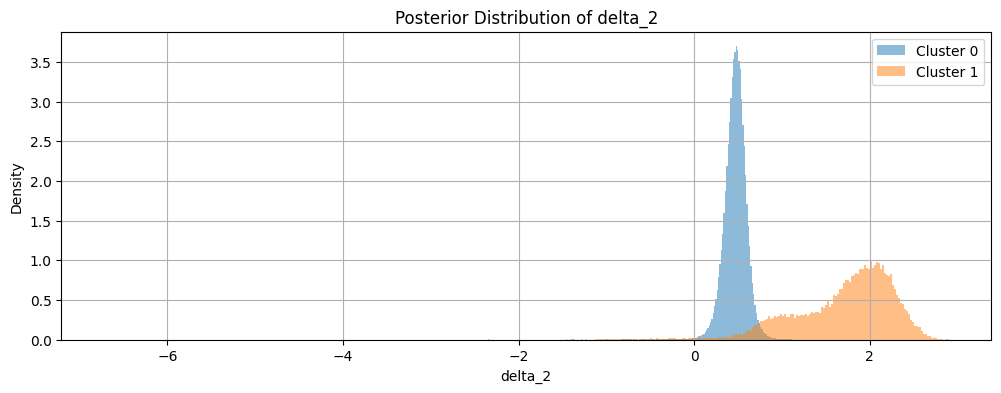

Cluster 0 - phi: Mean = 0.9486, 95% CI = [0.9301, 0.9656]
Cluster 1 - phi: Mean = 0.9727, 95% CI = [0.9632, 0.9799]


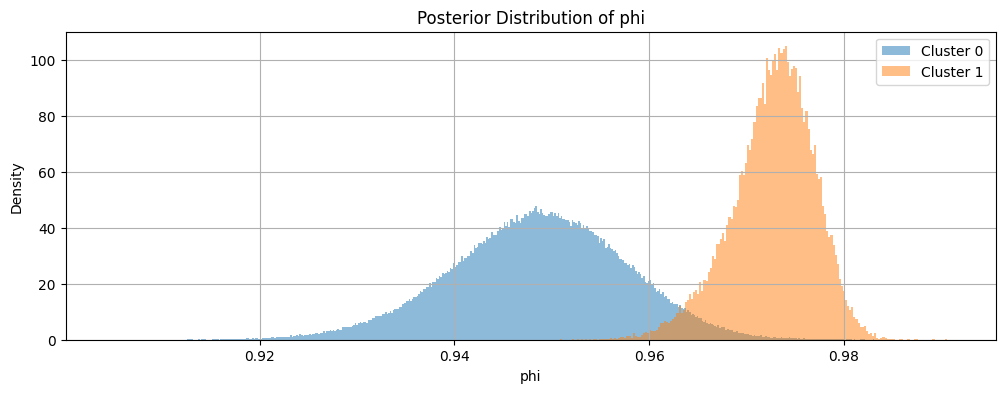

Cluster 0 - sigma^2: Mean = 0.0558, 95% CI = [0.0418, 0.0730]
Cluster 1 - sigma^2: Mean = 0.0395, 95% CI = [0.0282, 0.0531]


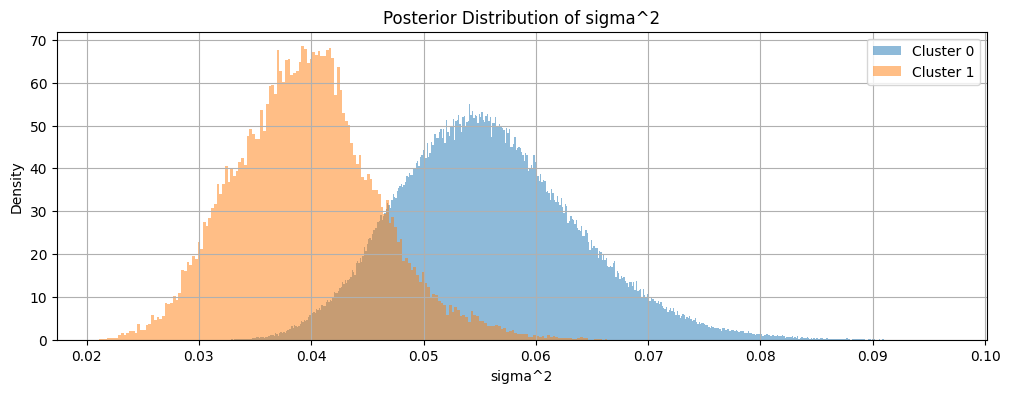

Cluster 0 - P_1_1: Mean = 0.9966, 95% CI = [0.9928, 0.9990]
Cluster 1 - P_1_1: Mean = 0.9951, 95% CI = [0.9800, 0.9994]


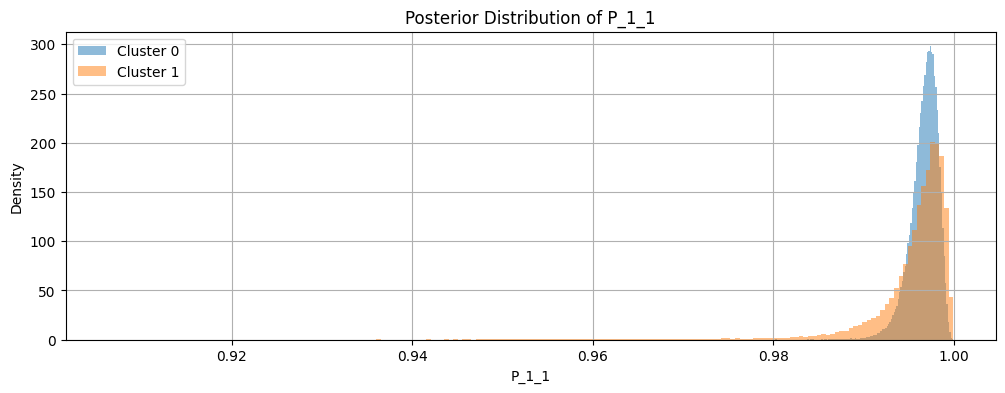

Cluster 0 - P_1_2: Mean = 0.0034, 95% CI = [0.0010, 0.0072]
Cluster 1 - P_1_2: Mean = 0.0049, 95% CI = [0.0006, 0.0200]


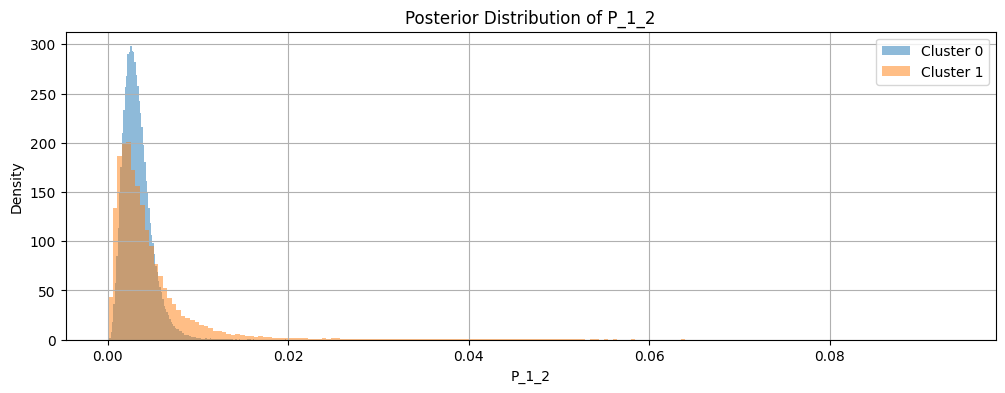

Cluster 0 - P_2_1: Mean = 0.0079, 95% CI = [0.0024, 0.0194]
Cluster 1 - P_2_1: Mean = 0.0869, 95% CI = [0.0198, 0.1898]


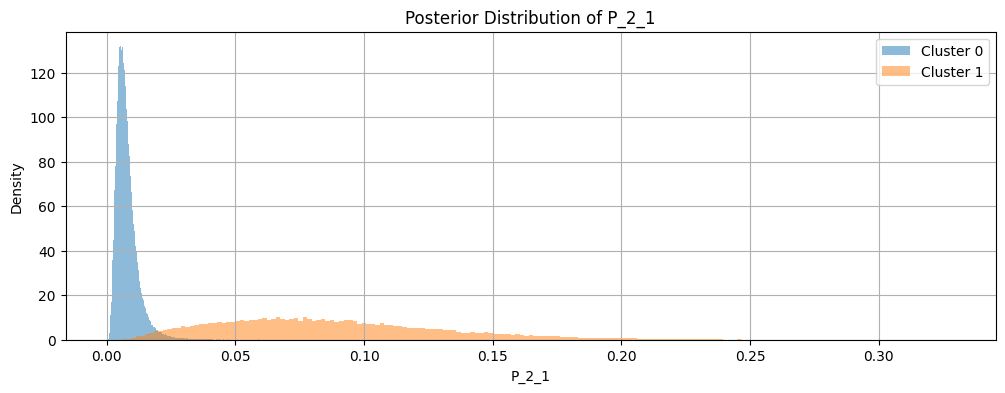

Cluster 0 - P_2_2: Mean = 0.9921, 95% CI = [0.9806, 0.9976]
Cluster 1 - P_2_2: Mean = 0.9131, 95% CI = [0.8102, 0.9802]


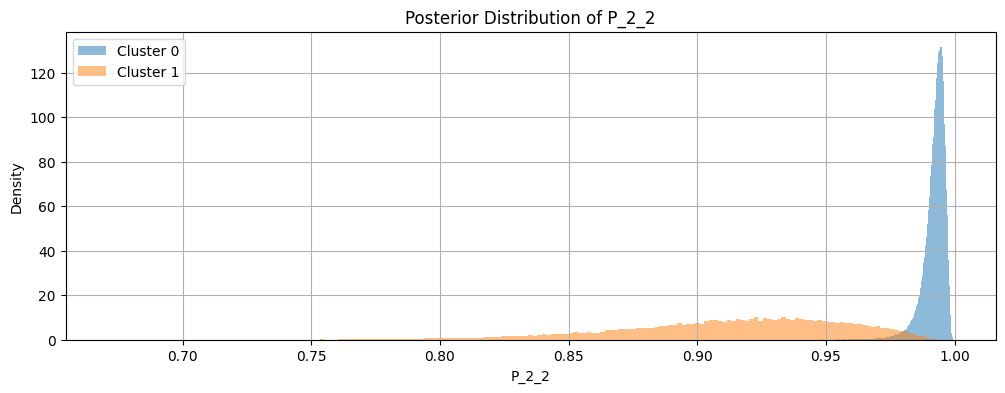

In [36]:
# Plot posterior distributions of parameters with denoted clusters
for name in df_constrained.columns:
    if name == "cluster":
        continue
    plt.figure(figsize=(12, 4))
    for cluster in [0, 1]:
        subset = df_constrained[df_constrained['cluster'] == cluster]
        mean_value = subset[name].mean()
        lo, hi = np.percentile(subset[name], [2.5, 97.5])
        print(f"Cluster {cluster} - {name}: Mean = {mean_value:.4f}, 95% CI = [{lo:.4f}, {hi:.4f}]")
        plt.hist(subset[name], bins=int(np.sqrt(len(subset))), alpha=0.5, label=f'Cluster {cluster}', density=True)
    plt.title(f'Posterior Distribution of {name}')
    plt.xlabel(name)
    plt.ylabel('Density')
    plt.legend()
    plt.grid()
    plt.show()

## Particle Marginal Metropolis-Hastings Results
We repeat the analysis for the PMMH results.

In [4]:
experiment_path = os.path.join(parent_dir, "experiments", "mssv_pmmh_sp500")
name = "sp500"

output_dir = os.path.join(experiment_path, name, "output")
results_dir = os.path.join(experiment_path, name, "results")
data_dir = os.path.join(parent_dir, "data", "real")

# Convert to pathlib.Path objects for easier path manipulation
output_dir = Path(output_dir)
results_dir = Path(results_dir)
data_dir = Path(data_dir)

In [5]:
# Get number of chain files from output_dir
chain_files = list(output_dir.glob("chain_*.h5"))
n_chains = len(chain_files)

# Dictionary to store chain data
chains_data = {}

for i, chain in enumerate(chain_files):
    with h5py.File(chain, "r") as h5f:
        thetas = h5f["thetas"][:]
        logmarliks = h5f["logmarliks"][:]

        trajectories = h5f["trajectories"][:]

        chains_data[i] = {
            "thetas": thetas,
            "logmarliks": logmarliks,
            "trajectories": trajectories
        }

n_params = chains_data[0]["thetas"].shape[1]
T_plus_1 = chains_data[0]["trajectories"].shape[1]

In [6]:
thetas = []
logmarliks = []
for i in range(n_chains):
    logmarliks.extend(chains_data[i]["logmarliks"])
    for j in range(chains_data[i]["thetas"].shape[0]):
        n_params = chains_data[i]["thetas"].shape[1]
        K = int(-1+np.sqrt(n_params+1))
        theta = MSSVParams(
            mu1=chains_data[i]["thetas"][j, 0],
            delta=chains_data[i]["thetas"][j, 1:K],
            phi=chains_data[i]["thetas"][j, K],
            eta2=chains_data[i]["thetas"][j, K+1],
            P=chains_data[i]["thetas"][j, K+2:].reshape((K, K))
        )
        thetas.append(theta.to_unconstrained())
        
thetas = np.array(thetas)
logmarliks = np.array(logmarliks)

In [7]:
trajectories = []
for i in range(n_chains):
    for j in range(chains_data[i]["trajectories"].shape[0]):
        trajectories.append(chains_data[i]["trajectories"][j])

In [8]:
# Release memory
del chains_data

In [9]:
parameter_names = generate_names(n_params)
print("Parameter names:", parameter_names)

Parameter names: ['mu1', 'delta_2', 'phi', 'sigma^2', 'logit_P_1_1', 'logit_P_2_1']


In [10]:
# Convert to pandas DataFrame for easier manipulation
df = pd.DataFrame(thetas, columns=parameter_names)
display(df.head())

,mu1,delta_2,phi,sigma^2,logit_P_1_1,logit_P_2_1
0,-9.957014,0.464776,1.803051,-2.967073,6.064093,-5.051142
1,-9.957014,0.464776,1.803051,-2.967073,6.064093,-5.051142
2,-9.957014,0.464776,1.803051,-2.967073,6.064093,-5.051142
3,-9.957014,0.464776,1.803051,-2.967073,6.064093,-5.051142
4,-9.957014,0.464776,1.803051,-2.967073,6.064093,-5.051142


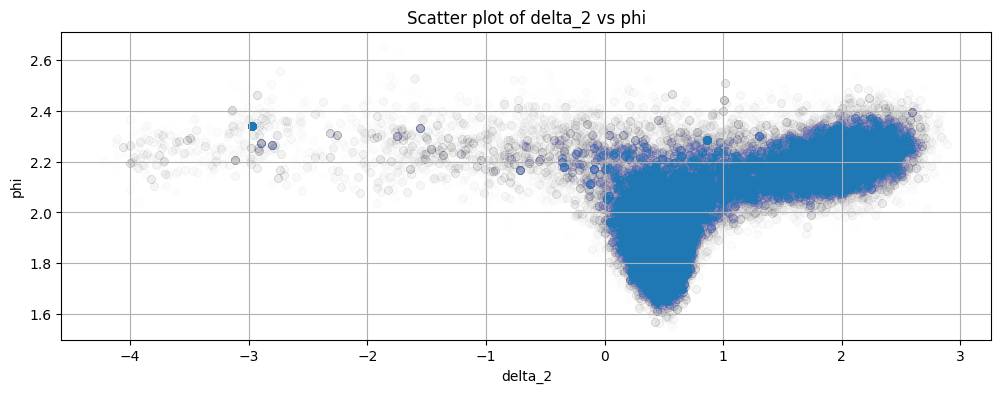

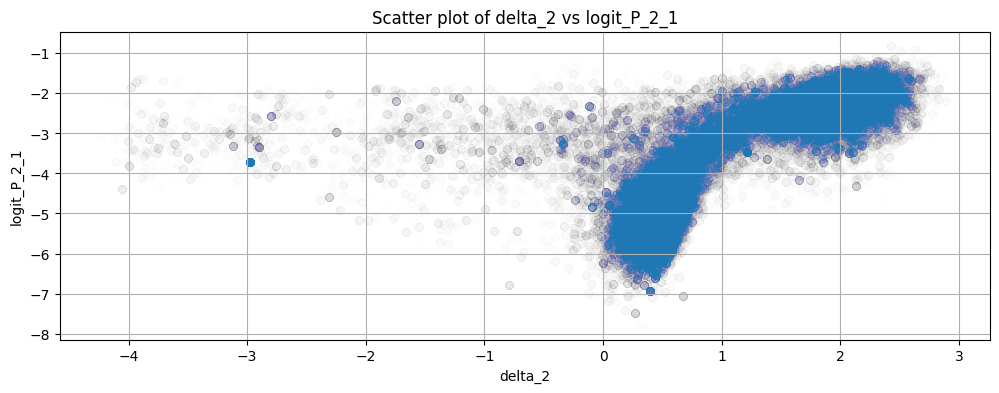

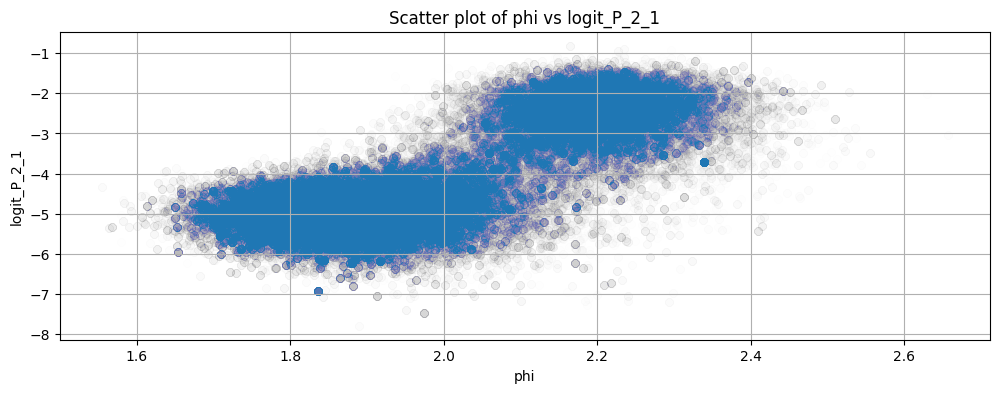

In [11]:
# delta_2, phi, and P_22 are at indices 1, K, and K*(K-1)+K+1 respectively in the unconstrained parameter vector. 

plt.figure(figsize=(12, 4))
plt.scatter(df["delta_2"], df["phi"], alpha=0.005)
plt.xlabel("delta_2")
plt.ylabel("phi")
plt.title("Scatter plot of delta_2 vs phi")
plt.grid()
plt.show()

plt.figure(figsize=(12, 4))
plt.scatter(df["delta_2"], df["logit_P_2_1"], alpha=0.005)
plt.xlabel("delta_2")
plt.ylabel("logit_P_2_1")
plt.title("Scatter plot of delta_2 vs logit_P_2_1")
plt.grid()
plt.show()

plt.figure(figsize=(12, 4))
plt.scatter(df["phi"], df["logit_P_2_1"], alpha=0.005)
plt.xlabel("phi")
plt.ylabel("logit_P_2_1")
plt.title("Scatter plot of phi vs logit_P_2_1")
plt.grid()
plt.show()

In [12]:
# Standardize the parameters for clustering using sklearn's StandardScaler
scaler = StandardScaler()
df_scaled = scaler.fit_transform(df)

In [13]:
# Perform KMeans clustering on the thetas using 2 clusters
kmeans = KMeans(n_clusters=2, random_state=42)
kmeans.fit(df_scaled)

# Add labels to the DataFrame
df['cluster'] = kmeans.labels_

In [15]:
# Change the cluster labels to match the previous clustering results
df['cluster'] = df['cluster'].map({0: 1, 1: 0})  # Swap labels to match previous clustering results

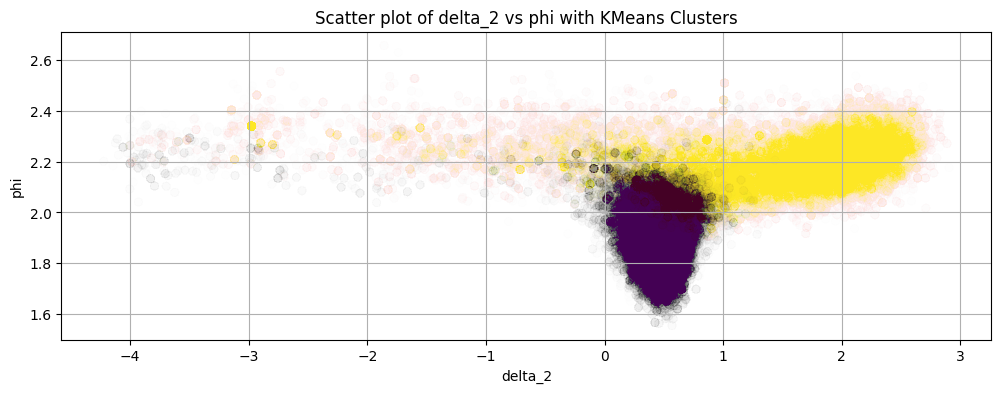

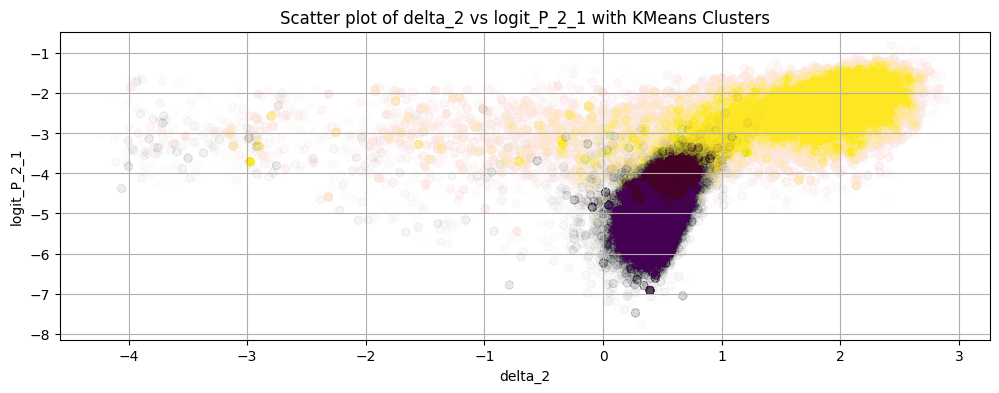

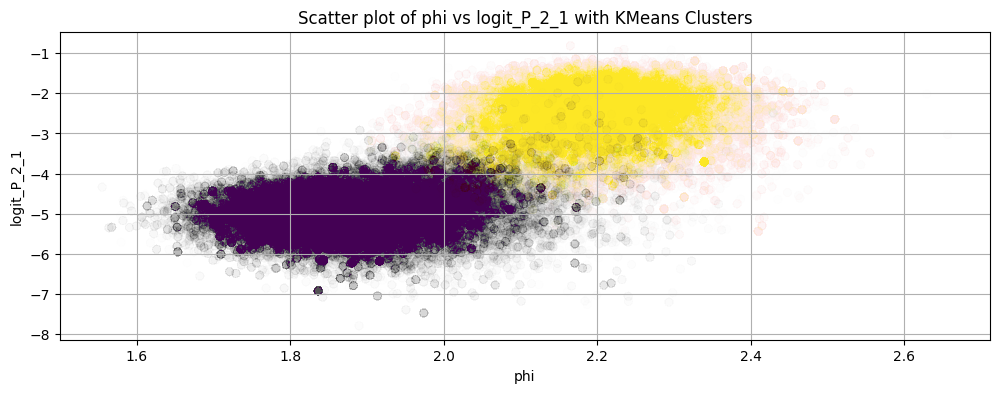

In [16]:
# Now you can visualize the clusters in the scatter plots
plt.figure(figsize=(12, 4))
plt.scatter(df["delta_2"], df["phi"], c=df['cluster'], cmap='viridis', alpha=0.005)
plt.xlabel("delta_2")
plt.ylabel("phi")
plt.title("Scatter plot of delta_2 vs phi with KMeans Clusters")
plt.grid(True)
plt.show()

plt.figure(figsize=(12, 4))
plt.scatter(df["delta_2"], df["logit_P_2_1"], c=df['cluster'], cmap='viridis', alpha=0.005)
plt.xlabel("delta_2")
plt.ylabel("logit_P_2_1")
plt.title("Scatter plot of delta_2 vs logit_P_2_1 with KMeans Clusters")
plt.grid(True)
plt.show()

plt.figure(figsize=(12, 4))
plt.scatter(df["phi"], df["logit_P_2_1"], c=df['cluster'], cmap='viridis', alpha=0.005)
plt.xlabel("phi")
plt.ylabel("logit_P_2_1")
plt.title("Scatter plot of phi vs logit_P_2_1 with KMeans Clusters")
plt.grid(True)
plt.show()


In [17]:
# Plot trajectories with "cluster" label 0
idx = df[df['cluster'] == 0].index

trajectories_cluster_0 = []
for i in idx:
    trajectories_cluster_0.append(trajectories[i])

In [18]:
print(f"Number of trajectories in cluster 0: {len(trajectories_cluster_0)}")

Number of trajectories in cluster 0: 213341


In [19]:
h_values = []
s_values = []
for traj in trajectories_cluster_0:
    h_values.append(traj[:, 0]) 
    s_values.append(traj[:, 1])

In [20]:
mean_h_values = np.empty((T_plus_1,))
mean_s_values = np.empty((T_plus_1,))
lower = np.empty(T_plus_1)
higher = np.empty(T_plus_1)

rng = np.random.default_rng(123)
subsampling_factor = 50  # Subsample factor to speed up computation
M = len(h_values)
idx = rng.choice(M, size=M // subsampling_factor, replace=False)

for t in range(T_plus_1):
    if t % 500 == 0:
        print(f"Processing time point {t}/{T_plus_1}...")
        
    column = [h_values[i][t] for i in idx]
    column = np.array(column)  # Convert to numpy array for mean and percentile calculations

    mean_h_values[t] = column.mean()
    lower[t], higher[t] = np.percentile(column, [2.5, 97.5])

    column_s = [s_values[i][t] for i in idx]
    column_s = np.array(column_s)  # Convert to numpy array for mean and percentile

    mean_s_values[t] = column_s.mean()

Processing time point 0/6664...
Processing time point 500/6664...
Processing time point 1000/6664...
Processing time point 1500/6664...
Processing time point 2000/6664...
Processing time point 2500/6664...
Processing time point 3000/6664...
Processing time point 3500/6664...
Processing time point 4000/6664...
Processing time point 4500/6664...
Processing time point 5000/6664...
Processing time point 5500/6664...
Processing time point 6000/6664...
Processing time point 6500/6664...


In [21]:
# Load the dates from real data
data = pd.read_csv(data_dir / "sp500" / "sp500.csv")
T = T_plus_1 - 1  # Exclude t=0 since it's the prior
# Keep only last T rows of data
data = data.tail(T)
dates = pd.to_datetime(data["Date"]).dt.date
dates = pd.to_datetime(dates).values

# Load the RV5 data
rv5_df = pd.read_csv(data_dir / "sp500" / "rv5_combined.csv")
rv5_values = rv5_df["RV5"].values
rv5_dates = pd.to_datetime(rv5_df["Date"]).dt.date
rv5_dates = pd.to_datetime(rv5_dates).values

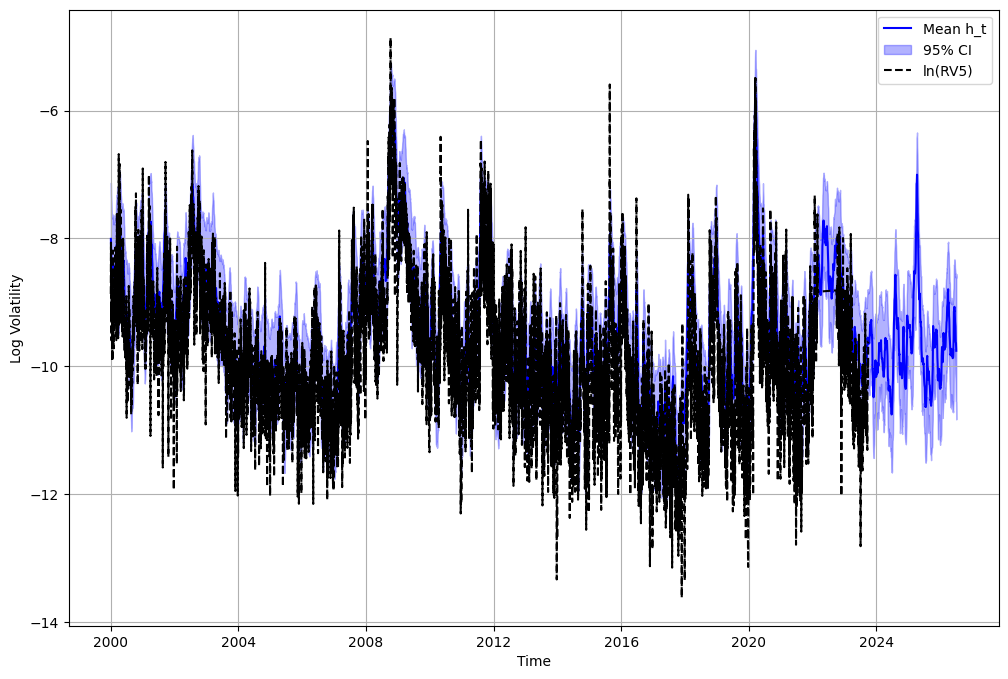

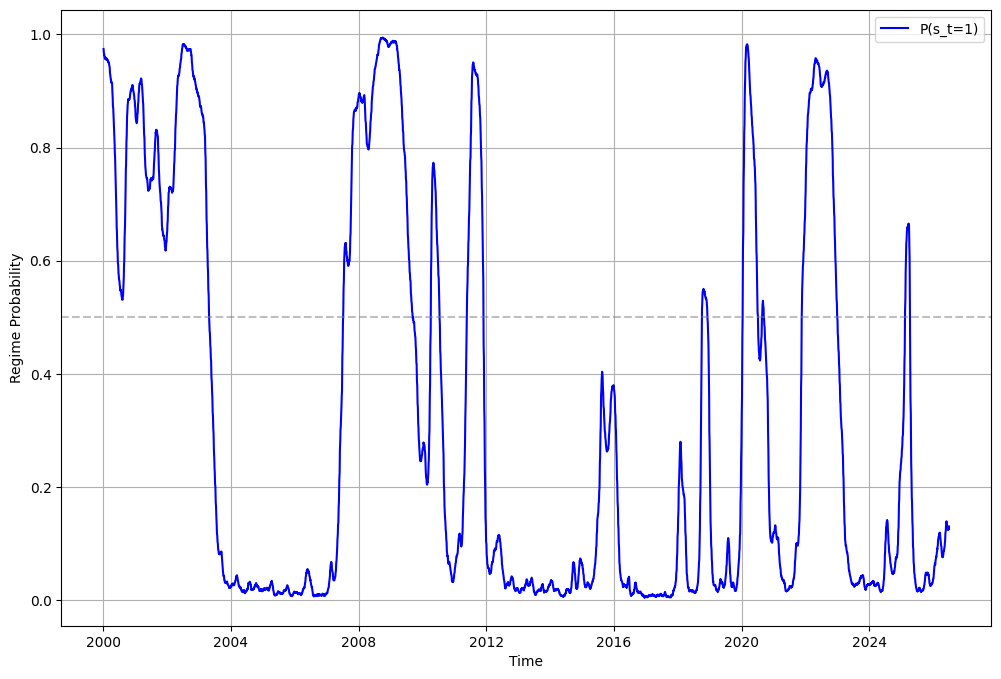

In [22]:
plt.figure(figsize=(12, 8))
plt.plot(dates, mean_h_values[1:], label="Mean h_t", color='blue')  
plt.fill_between(dates, lower[1:], higher[1:], color='blue', alpha=0.3, label="95% CI")
plt.plot(rv5_dates, np.log(rv5_values), label="ln(RV5)", color='black', linestyle='--')
plt.xlabel("Time")
plt.ylabel("Log Volatility")
plt.legend()
plt.grid()
plt.show()

plt.figure(figsize=(12, 8))
plt.plot(dates, mean_s_values[1:], label="P(s_t=1)", color='blue')
plt.axhline(0.5, color='grey', linestyle='--', alpha=0.5)
plt.xlabel("Time")
plt.ylabel("Regime Probability")
plt.legend()
plt.grid()
plt.show()

In [23]:
# Now repeat the same process for cluster 1
idx = df[df['cluster'] == 1].index

trajectories_cluster_1 = []
for i in idx:
    trajectories_cluster_1.append(trajectories[i])

In [24]:
print(f"Number of trajectories in cluster 1: {len(trajectories_cluster_1)}")

Number of trajectories in cluster 1: 96659


In [25]:
h_values = []
s_values = []
for traj in trajectories_cluster_1:
    h_values.append(traj[:, 0]) 
    s_values.append(traj[:, 1])

In [26]:
mean_h_values = np.empty((T_plus_1,))
mean_s_values = np.empty((T_plus_1,))
lower = np.empty(T_plus_1)
higher = np.empty(T_plus_1)

rng = np.random.default_rng(123)
subsampling_factor = 50  # Subsample factor to speed up computation
M = len(h_values)
idx = rng.choice(M, size=M // subsampling_factor, replace=False)

for t in range(T_plus_1):
    if t % 500 == 0:
        print(f"Processing time point {t}/{T_plus_1}...")
        
    column = [h_values[i][t] for i in idx]
    column = np.array(column)  # Convert to numpy array for mean and percentile calculations

    mean_h_values[t] = column.mean()
    lower[t], higher[t] = np.percentile(column, [2.5, 97.5])

    column_s = [s_values[i][t] for i in idx]
    column_s = np.array(column_s)  # Convert to numpy array for mean and percentile

    mean_s_values[t] = column_s.mean()

Processing time point 0/6664...
Processing time point 500/6664...
Processing time point 1000/6664...
Processing time point 1500/6664...
Processing time point 2000/6664...
Processing time point 2500/6664...
Processing time point 3000/6664...
Processing time point 3500/6664...
Processing time point 4000/6664...
Processing time point 4500/6664...
Processing time point 5000/6664...
Processing time point 5500/6664...
Processing time point 6000/6664...
Processing time point 6500/6664...


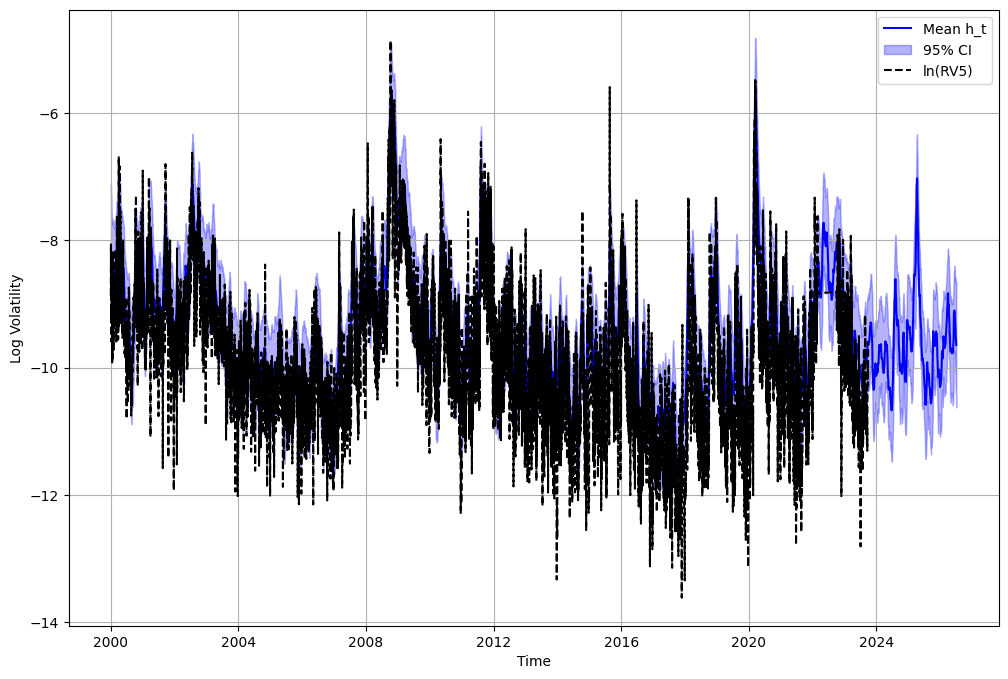

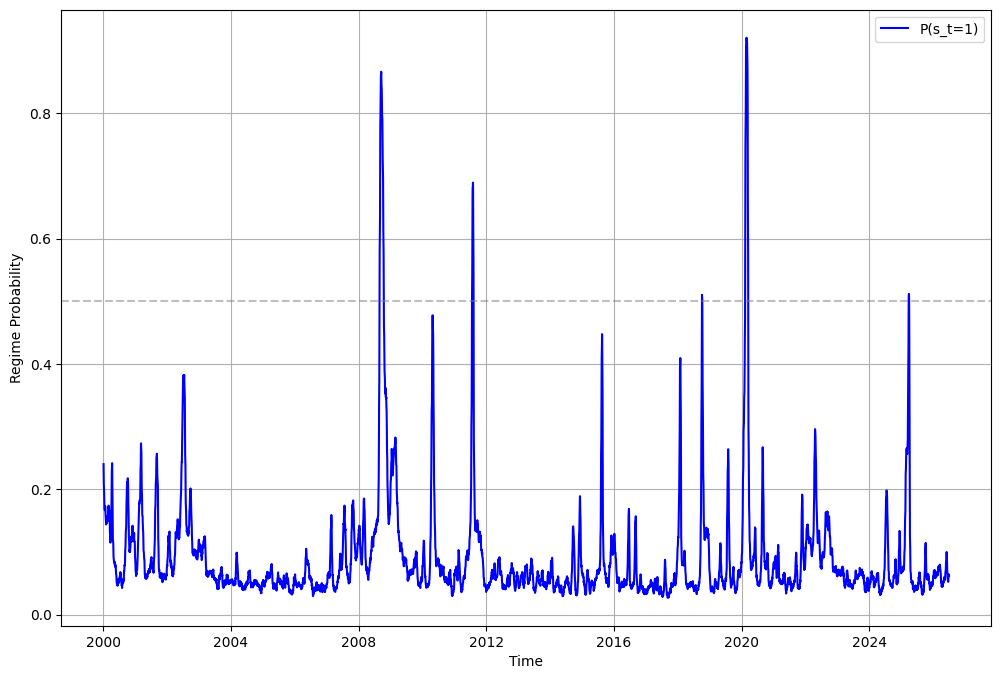

In [27]:
plt.figure(figsize=(12, 8))
plt.plot(dates, mean_h_values[1:], label="Mean h_t", color='blue')  
plt.fill_between(dates, lower[1:], higher[1:], color='blue', alpha=0.3, label="95% CI")
plt.plot(rv5_dates, np.log(rv5_values), label="ln(RV5)", color='black', linestyle='--')
plt.xlabel("Time")
plt.ylabel("Log Volatility")
plt.legend()
plt.grid()
plt.show()

plt.figure(figsize=(12, 8))
plt.plot(dates, mean_s_values[1:], label="P(s_t=1)", color='blue')
plt.axhline(0.5, color='grey', linestyle='--', alpha=0.5)
plt.xlabel("Time")
plt.ylabel("Regime Probability")
plt.legend()
plt.grid()
plt.show()

In [28]:
# Transform df parameters back to constrained space for easier interpretation
df_constrained = df.copy()
df_constrained["phi"] = df_constrained["phi"].apply(lambda x: np.tanh(x))  # Transform phi back to (-1, 1)
df_constrained["sigma^2"] = df_constrained["sigma^2"].apply(lambda x: np.exp(x))  # Transform sigma^2 back to positive values
df_constrained["P_1_1"] = df_constrained["logit_P_1_1"].apply(lambda x: 1 / (1 + np.exp(-x)))  # Transform logit_P_1_1 back to (0, 1)
df_constrained["P_1_2"] = 1 - df_constrained["P_1_1"]  # Since P_1_2 = 1 - P_1_1
df_constrained["P_2_1"] = df_constrained["logit_P_2_1"].apply(lambda x: 1 / (1 + np.exp(-x)))  # Transform logit_P_2_1 back to (0, 1)
df_constrained["P_2_2"] = 1 - df_constrained["P_2_1"]  # Since P_2_2 = 1 - P_2_1

# Drop other columns
df_constrained = df_constrained[["mu1", "delta_2", "phi", "sigma^2", "P_1_1", "P_1_2", "P_2_1", "P_2_2", "cluster"]]

In [29]:
# Print number of samples in each cluster
cluster_counts = df_constrained['cluster'].value_counts()
print("Number of samples in each cluster:")
print(cluster_counts)

Number of samples in each cluster:
cluster
0    213341
1     96659
Name: count, dtype: int64


Cluster 0 - mu1: Mean = -9.9543, 95% CI = [-10.1706, -9.6993]
Cluster 1 - mu1: Mean = -9.6966, 95% CI = [-10.0810, -9.3891]


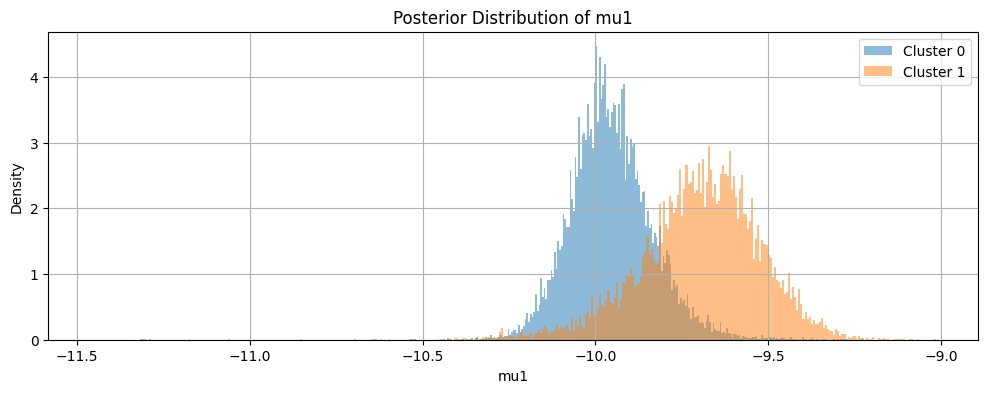

Cluster 0 - delta_2: Mean = 0.4372, 95% CI = [0.1228, 0.7174]
Cluster 1 - delta_2: Mean = 1.4152, 95% CI = [-1.4895, 2.4922]


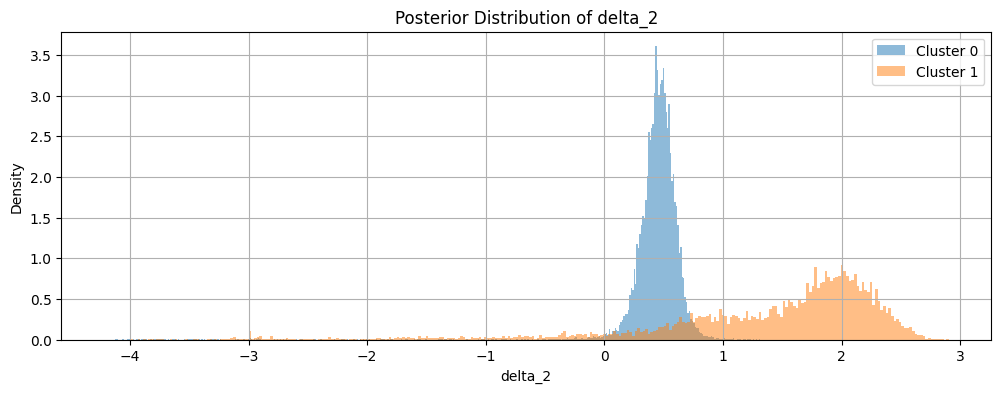

Cluster 0 - phi: Mean = 0.9540, 95% CI = [0.9361, 0.9708]
Cluster 1 - phi: Mean = 0.9751, 95% CI = [0.9661, 0.9827]


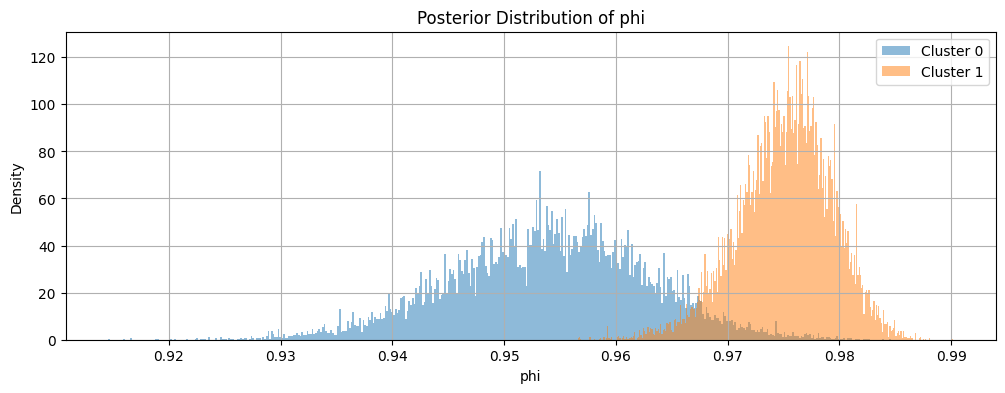

Cluster 0 - sigma^2: Mean = 0.0526, 95% CI = [0.0397, 0.0686]
Cluster 1 - sigma^2: Mean = 0.0379, 95% CI = [0.0263, 0.0507]


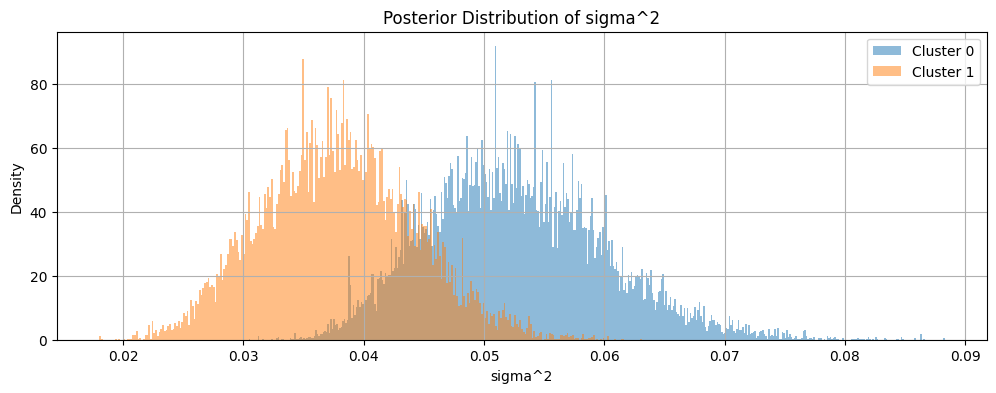

Cluster 0 - P_1_1: Mean = 0.9966, 95% CI = [0.9923, 0.9991]
Cluster 1 - P_1_1: Mean = 0.9917, 95% CI = [0.9530, 0.9992]


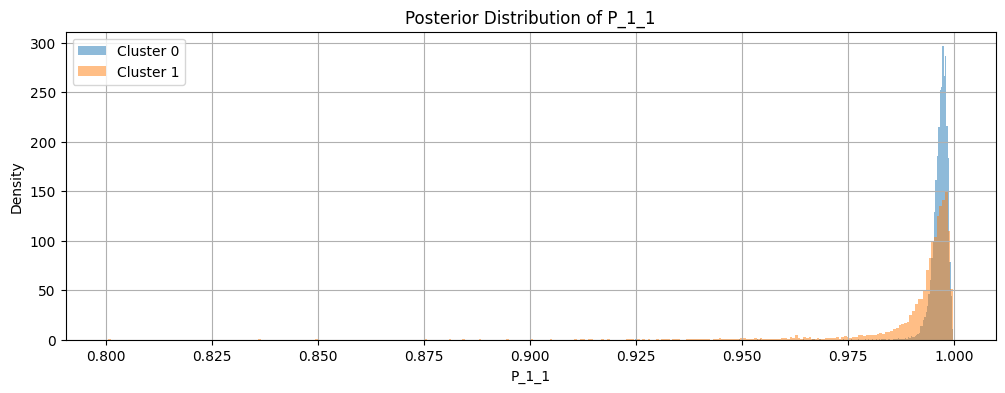

Cluster 0 - P_1_2: Mean = 0.0034, 95% CI = [0.0009, 0.0077]
Cluster 1 - P_1_2: Mean = 0.0083, 95% CI = [0.0008, 0.0470]


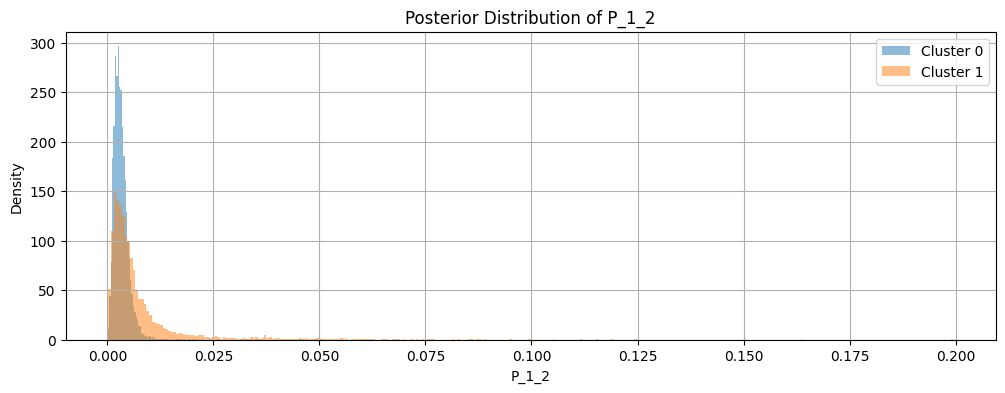

Cluster 0 - P_2_1: Mean = 0.0080, 95% CI = [0.0022, 0.0208]
Cluster 1 - P_2_1: Mean = 0.0815, 95% CI = [0.0172, 0.1788]


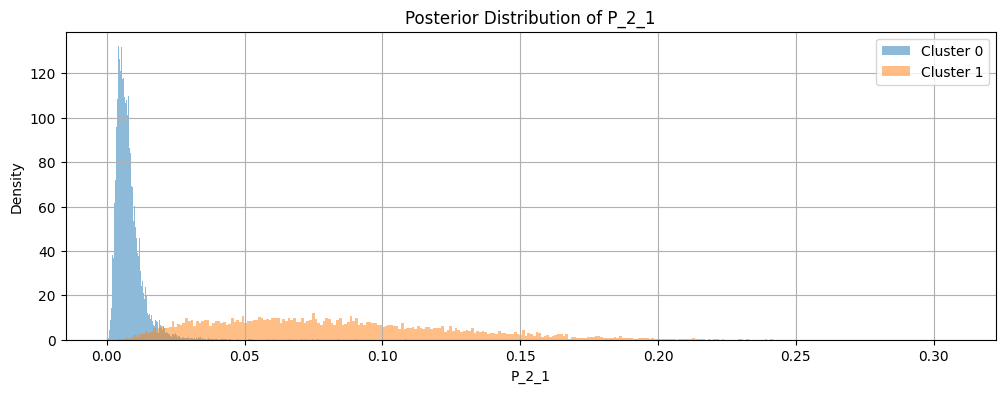

Cluster 0 - P_2_2: Mean = 0.9920, 95% CI = [0.9792, 0.9978]
Cluster 1 - P_2_2: Mean = 0.9185, 95% CI = [0.8212, 0.9828]


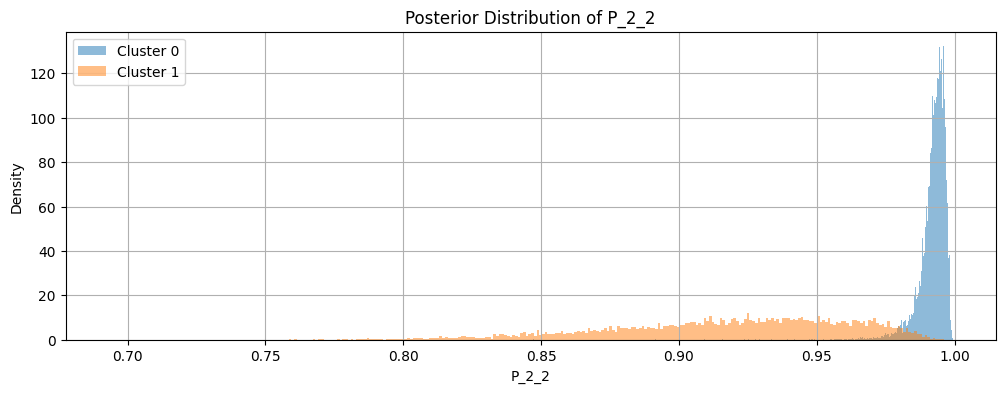

In [30]:
# Plot posterior distributions of parameters with denoted clusters
for name in df_constrained.columns:
    if name == "cluster":
        continue
    plt.figure(figsize=(12, 4))
    for cluster in [0, 1]:
        subset = df_constrained[df_constrained['cluster'] == cluster]
        mean_value = subset[name].mean()
        lo, hi = np.percentile(subset[name], [2.5, 97.5])
        print(f"Cluster {cluster} - {name}: Mean = {mean_value:.4f}, 95% CI = [{lo:.4f}, {hi:.4f}]")
        plt.hist(subset[name], bins=int(np.sqrt(len(subset))), alpha=0.5, label=f'Cluster {cluster}', density=True)
    plt.title(f'Posterior Distribution of {name}')
    plt.xlabel(name)
    plt.ylabel('Density')
    plt.legend()
    plt.grid()
    plt.show()

## SMC^2 Results

We repeat the same procedure for the SMC^2 results. The special feature of SMC^2 is that it allows for online inference, which means that we could analyze the modes at every time step. But for comparison and simplicity we will analyze the distributions only at the last time step. 

In [3]:
experiment_path = os.path.join(parent_dir, "experiments", "mssv_smc2_sp500")
name = "sp500"

output_dir = os.path.join(experiment_path, name, "output")
results_dir = os.path.join(experiment_path, name, "results")
data_dir = os.path.join(parent_dir, "data", "real")

# Convert to pathlib.Path objects for easier path manipulation
output_dir = Path(output_dir)
results_dir = Path(results_dir)
data_dir = Path(data_dir)

In [4]:
def weighted_quantile(values, quantiles, sample_weight):
    """
    Compute weighted quantiles for 1D samples.

    Parameters
    ----------
    values : ndarray, shape (N,)
    quantiles : array-like in [0, 1]
    sample_weight : ndarray, shape (N,)

    Returns
    -------
    ndarray
        Quantile values.
    """

    values = np.asarray(values)
    quantiles = np.asarray(quantiles)
    sample_weight = np.asarray(sample_weight)

    sorter = np.argsort(values)

    values = values[sorter]
    weights = sample_weight[sorter]

    cdf = np.cumsum(weights)
    cdf /= cdf[-1]

    return np.interp(quantiles, cdf, values)

def weighted_credible_interval(values, weights, alpha=0.05):
    """
    Compute weighted credible intervals componentwise.

    Parameters
    ----------
    values : ndarray
        Shape (N, ...)
        where N = number of particles.

    weights : ndarray
        Shape (N,)

    alpha : float
        Credible level. alpha=0.05 -> 95% CI.

    Returns
    -------
    lower : ndarray
    upper : ndarray

    Both have shape values.shape[1:].
    """

    values = np.asarray(values)

    # -----------------------------------------
    # scalar parameter
    # -----------------------------------------
    if values.ndim == 1:
        q = weighted_quantile(
            values,
            [alpha / 2, 1 - alpha / 2],
            weights
        )
        return q[0], q[1]

    # -----------------------------------------
    # flatten parameter dimensions
    # -----------------------------------------
    original_shape = values.shape[1:]

    flat = values.reshape(values.shape[0], -1)

    lower = np.empty(flat.shape[1])
    upper = np.empty(flat.shape[1])

    for j in range(flat.shape[1]):

        q = weighted_quantile(
            flat[:, j],
            [alpha / 2, 1 - alpha / 2],
            weights
        )

        lower[j] = q[0]
        upper[j] = q[1]

    lower = lower.reshape(original_shape)
    upper = upper.reshape(original_shape)

    return lower, upper

def normalize_logweights(logw):
    """
    Stable normalization of log weights.
    """
    m = np.max(logw)
    w = np.exp(logw - m)
    return w / np.sum(w)

In [5]:
with h5py.File(output_dir / "theta_history.h5", "r") as h5f:
    theta = h5f["theta"][-1]  # Get the last time step
    logweights = h5f["logweights"][-1]

N_theta, n_params = theta.shape

parameter_names = generate_names(n_params)
K = int(-1+np.sqrt(n_params+1))
print("Parameter names:", parameter_names)

Parameter names: ['mu1', 'delta_2', 'phi', 'sigma^2', 'logit_P_1_1', 'logit_P_2_1']


In [6]:
# Convert theta from constrained to unconstrained space for clustering
theta = np.array([MSSVParams(
    mu1=theta[i, 0],
    delta=theta[i, 1:K],
    phi=theta[i, K],
    eta2=theta[i, K+1],
    P=theta[i, K+2:].reshape((K, K))
).to_unconstrained() for i in range(N_theta)])
print("Shape of thetas array:", theta.shape)

Shape of thetas array: (8000, 6)


In [7]:
# Convert to pandas DataFrame for easier manipulation
df = pd.DataFrame(theta, columns=parameter_names)
display(df.head())

,mu1,delta_2,phi,sigma^2,logit_P_1_1,logit_P_2_1
0,-9.827475,0.496399,2.133207,-3.115756,5.300909,-3.858353
1,-9.749393,0.481211,1.961301,-2.951970,6.086361,-5.230107
2,-10.083189,0.888499,2.190880,-3.179223,3.813912,-2.593734
3,-10.008980,0.726383,1.958523,-2.994823,4.801236,-3.704180
4,-9.987113,0.396335,1.817775,-2.915985,5.708236,-4.984177


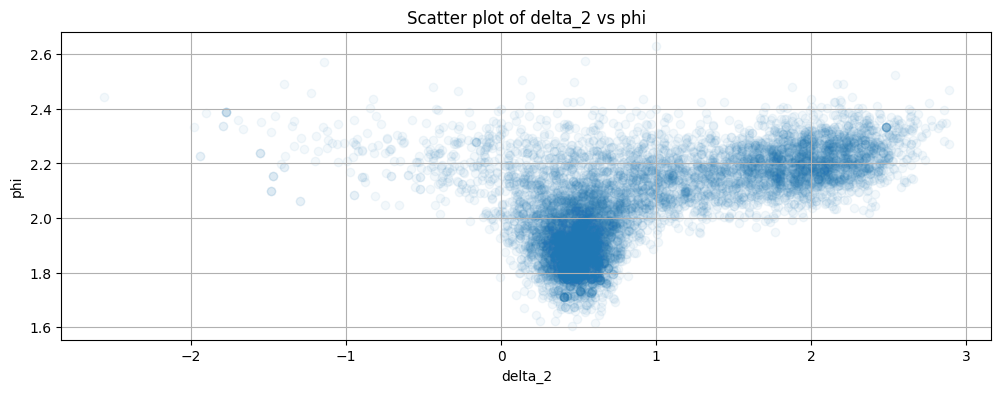

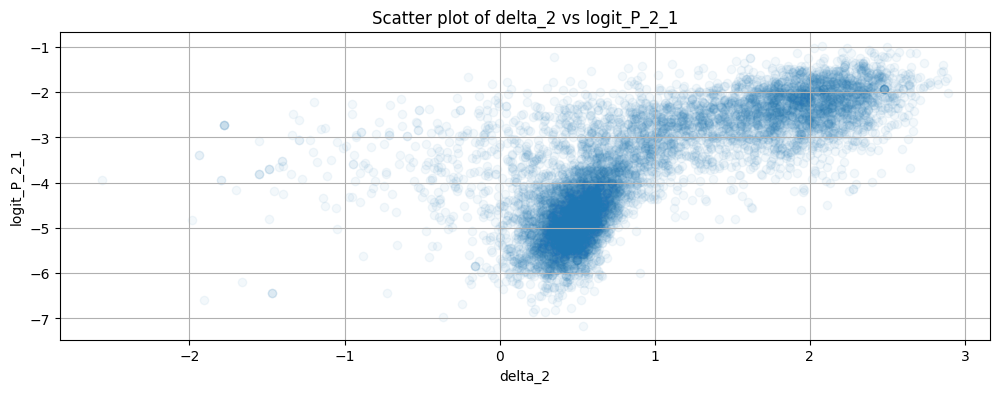

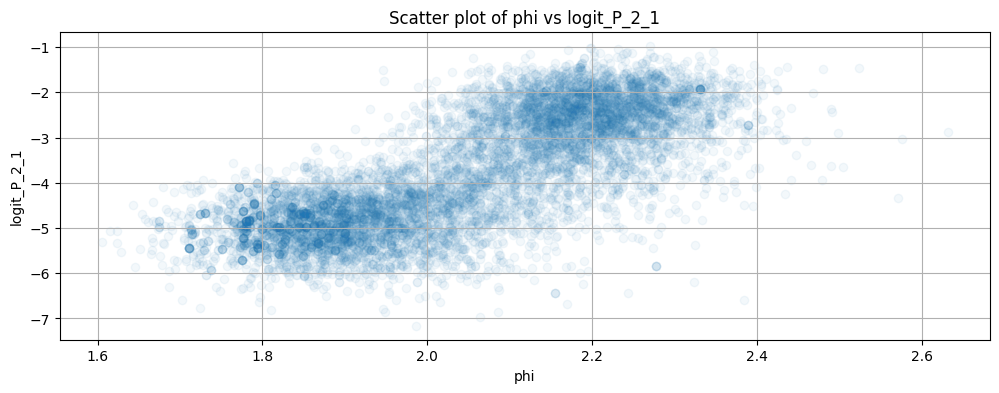

In [8]:
# delta_2, phi, and P_22 are at indices 1, K, and K*(K-1)+K+1 respectively in the unconstrained parameter vector. 

plt.figure(figsize=(12, 4))
plt.scatter(df["delta_2"], df["phi"], alpha=0.05)
plt.xlabel("delta_2")
plt.ylabel("phi")
plt.title("Scatter plot of delta_2 vs phi")
plt.grid()
plt.show()

plt.figure(figsize=(12, 4))
plt.scatter(df["delta_2"], df["logit_P_2_1"], alpha=0.05)
plt.xlabel("delta_2")
plt.ylabel("logit_P_2_1")
plt.title("Scatter plot of delta_2 vs logit_P_2_1")
plt.grid()
plt.show()

plt.figure(figsize=(12, 4))
plt.scatter(df["phi"], df["logit_P_2_1"], alpha=0.05)
plt.xlabel("phi")
plt.ylabel("logit_P_2_1")
plt.title("Scatter plot of phi vs logit_P_2_1")
plt.grid()
plt.show()

In [9]:
# Standardize the parameters for clustering using sklearn's StandardScaler
scaler = StandardScaler()
df_scaled = scaler.fit_transform(df)

In [10]:
# Perform KMeans clustering on the thetas using 2 clusters
kmeans = KMeans(n_clusters=2, random_state=42)
kmeans.fit(df_scaled)

# Add labels to the DataFrame
df['cluster'] = kmeans.labels_

In [11]:
# Just switch labels between 0 and 1, in order to match the previous clustering results
df['cluster'] = 1 - df['cluster']

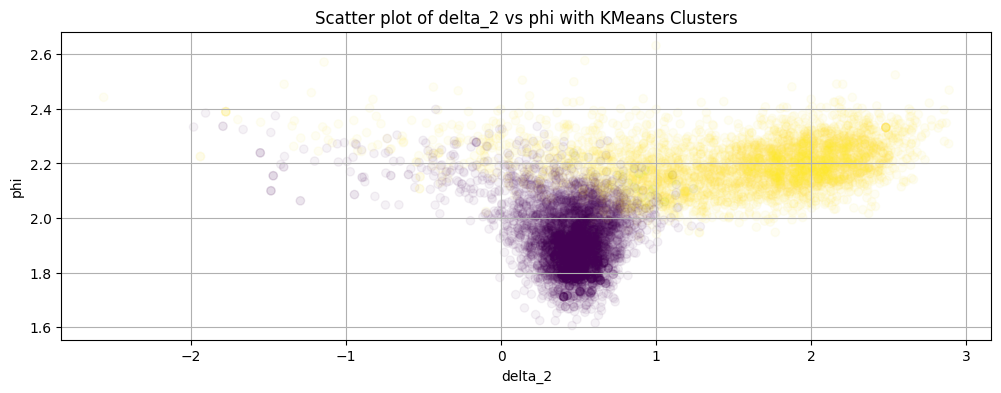

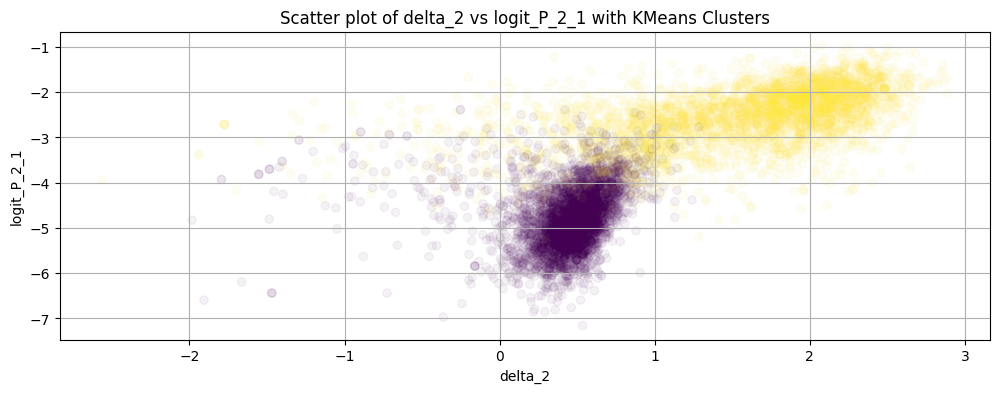

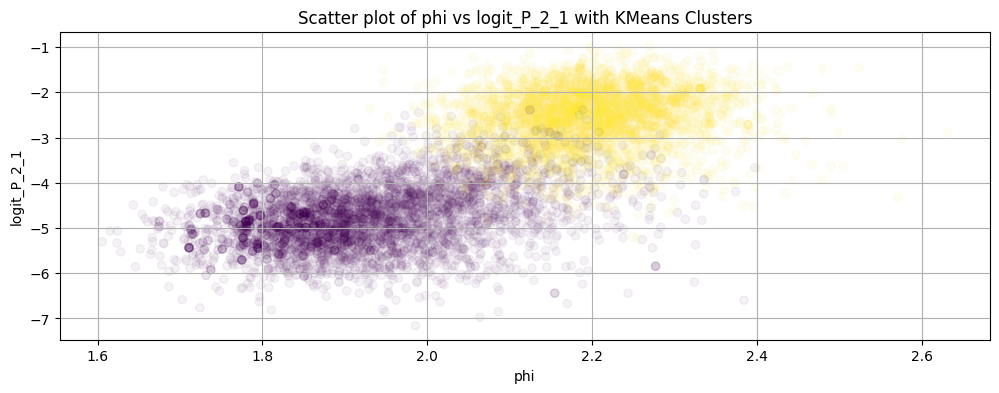

In [12]:
# Now you can visualize the clusters in the scatter plots
plt.figure(figsize=(12, 4))
plt.scatter(df["delta_2"], df["phi"], c=df['cluster'], cmap='viridis', alpha=0.05)
plt.xlabel("delta_2")
plt.ylabel("phi")
plt.title("Scatter plot of delta_2 vs phi with KMeans Clusters")
plt.grid(True)
plt.show()

plt.figure(figsize=(12, 4))
plt.scatter(df["delta_2"], df["logit_P_2_1"], c=df['cluster'], cmap='viridis', alpha=0.05)
plt.xlabel("delta_2")
plt.ylabel("logit_P_2_1")
plt.title("Scatter plot of delta_2 vs logit_P_2_1 with KMeans Clusters")
plt.grid(True)
plt.show()

plt.figure(figsize=(12, 4))
plt.scatter(df["phi"], df["logit_P_2_1"], c=df['cluster'], cmap='viridis', alpha=0.05)
plt.xlabel("phi")
plt.ylabel("logit_P_2_1")
plt.title("Scatter plot of phi vs logit_P_2_1 with KMeans Clusters")
plt.grid(True)
plt.show()


In [13]:
# Load the trajectories from the SMC2 output
with h5py.File(output_dir / "state_history.h5", "r") as h5f:
    trajectories = h5f["trajectories"][:]

N_theta, Tp1, save_factor, state_dim = trajectories.shape

In [14]:
print("Shape of trajectories array:", trajectories.shape)

Shape of trajectories array: (8000, 6664, 5, 2)


In [15]:
# Plot trajectories with "cluster" label 0
idx = df[df['cluster'] == 0].index
trajectories_cluster_0 = []
for i in idx:
    trajectories_cluster_0.append(trajectories[i])
trajectories_cluster_0 = np.array(trajectories_cluster_0)
print(f"Shape of trajectories for cluster 0: {trajectories_cluster_0.shape}")

Shape of trajectories for cluster 0: (4392, 6664, 5, 2)


In [16]:
N_0 = trajectories_cluster_0.shape[0]  # Number of thetas in cluster 0. The number of trajectories in cluster 0 is N_0 * save_factor, since each theta has save_factor trajectories.
trajectories_cluster_0 = (
    np.swapaxes(trajectories_cluster_0, 1, 2)      # (N_0, save_factor, T+1, state_dim)
    .reshape(N_0 * save_factor, Tp1, state_dim)
)

In [17]:
# Normalize the log weights for cluster 0
logweights_0 = normalize_logweights(logweights[idx])
traj_weights_0 = np.repeat(logweights_0, save_factor)  # Repeat each weight save_factor times to match the number of trajectories
traj_weights_0 /= np.sum(traj_weights_0)  # Normalize to sum to 1

In [18]:
# Load the dates from real data
data = pd.read_csv(data_dir / "sp500" / "sp500.csv")
T = Tp1 - 1  # Exclude t=0 since it's the prior
# Keep only last T rows of data
data = data.tail(T)
dates = pd.to_datetime(data["Date"]).dt.date
dates = pd.to_datetime(dates).values

# Load the RV5 data
rv5_df = pd.read_csv(data_dir / "sp500" / "rv5_combined.csv")
rv5_values = rv5_df["RV5"].values
rv5_dates = pd.to_datetime(rv5_df["Date"]).dt.date
rv5_dates = pd.to_datetime(rv5_dates).values

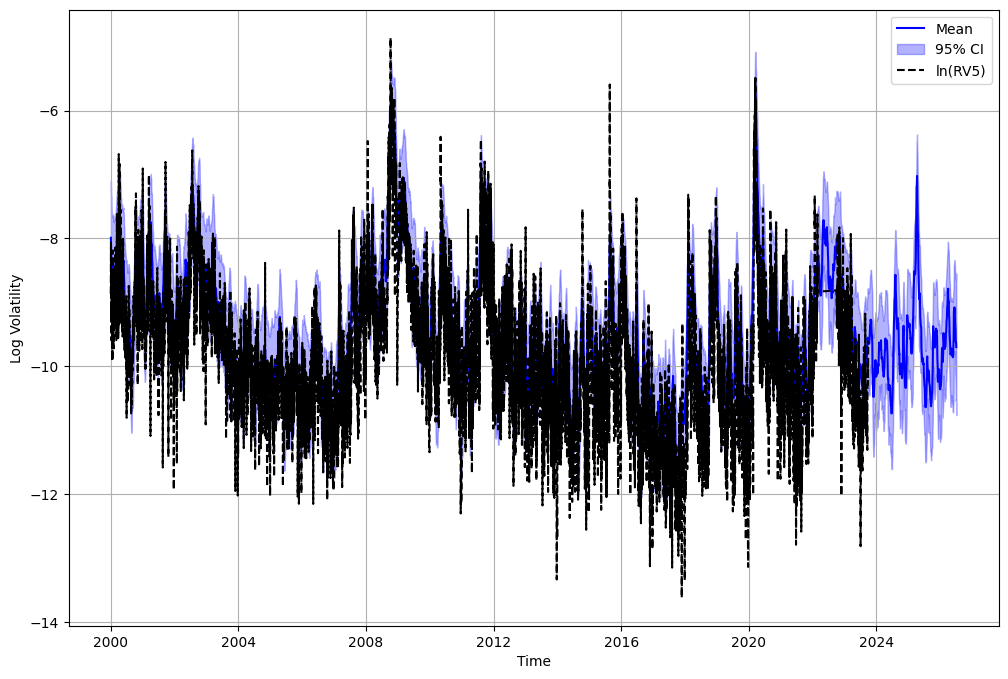

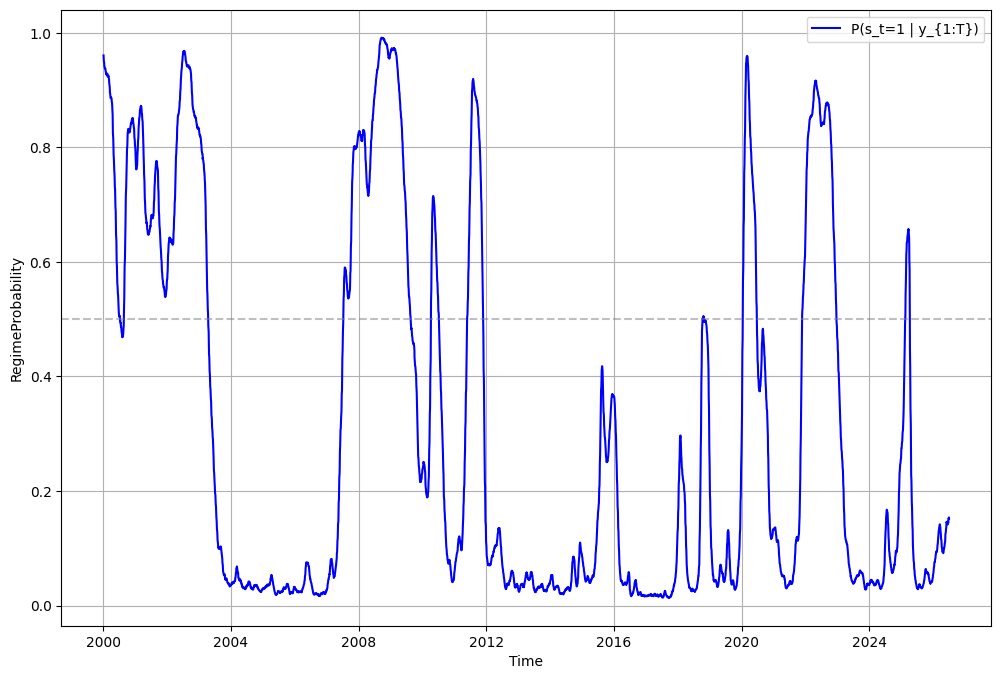

In [19]:
# -----------------------
# Smoothing h values
# -----------------------
h_values = trajectories_cluster_0[:, :, 0]     # shape (N_theta * save_factor, T+1)
means = np.sum(traj_weights_0[:, None] * h_values, axis=0)
lower, higher = weighted_credible_interval(h_values, traj_weights_0, alpha=0.05)

plt.figure(figsize=(12, 8))
plt.plot(dates, means[1:], label="Mean", color='blue')                  # Dont plot prior
plt.fill_between(dates, lower[1:], higher[1:], alpha=0.3, label="95% CI", color='blue')     # Same here
plt.plot(rv5_dates, np.log(rv5_values), label="ln(RV5)", color='black', linestyle='--')
plt.xlabel("Time")
plt.ylabel("Log Volatility")
plt.grid(True)
plt.legend()
ax = plt.gca()
ylims = ax.get_ylim()
plt.show()
plt.close()

# -----------------------
# Smoothing s values
# -----------------------
s_values = trajectories_cluster_0[:, :, 1]    # shape (N_theta * save_factor, T+1)
regime_probs = np.sum(traj_weights_0[:, None] * s_values, axis=0)

plt.figure(figsize=(12, 8))
plt.plot(dates, regime_probs[1:], label="P(s_t=1 | y_{1:T})", color='blue')                  # Dont plot prior
plt.axhline(0.5, color="grey", linestyle="--", alpha=0.5)
plt.xlabel("Time")
plt.ylabel("RegimeProbability")
plt.grid(True)
plt.legend()  
plt.show()
plt.close()

In [20]:
# Now repeat the same process for cluster 1
idx = df[df['cluster'] == 1].index

trajectories_cluster_1 = []
for i in idx:
    trajectories_cluster_1.append(trajectories[i])
trajectories_cluster_1 = np.array(trajectories_cluster_1)
print(f"Shape of trajectories for cluster 1: {trajectories_cluster_1.shape}")

Shape of trajectories for cluster 1: (3608, 6664, 5, 2)


In [21]:
N_1 = trajectories_cluster_1.shape[0]  # Number of thetas in cluster 1. The number of trajectories in cluster 1 is N_1 * save_factor, since each theta has save_factor trajectories.
trajectories_cluster_1 = (
    np.swapaxes(trajectories_cluster_1, 1, 2)      # (N_1, save_factor, T+1, state_dim)
    .reshape(N_1 * save_factor, Tp1, state_dim)
)

In [22]:
# Normalize the log weights for cluster 1
logweights_1 = normalize_logweights(logweights[idx])
traj_weights_1 = np.repeat(logweights_1, save_factor)  # Repeat each weight save_factor times to match the number of trajectories
traj_weights_1 /= np.sum(traj_weights_1)  # Normalize to sum to 1

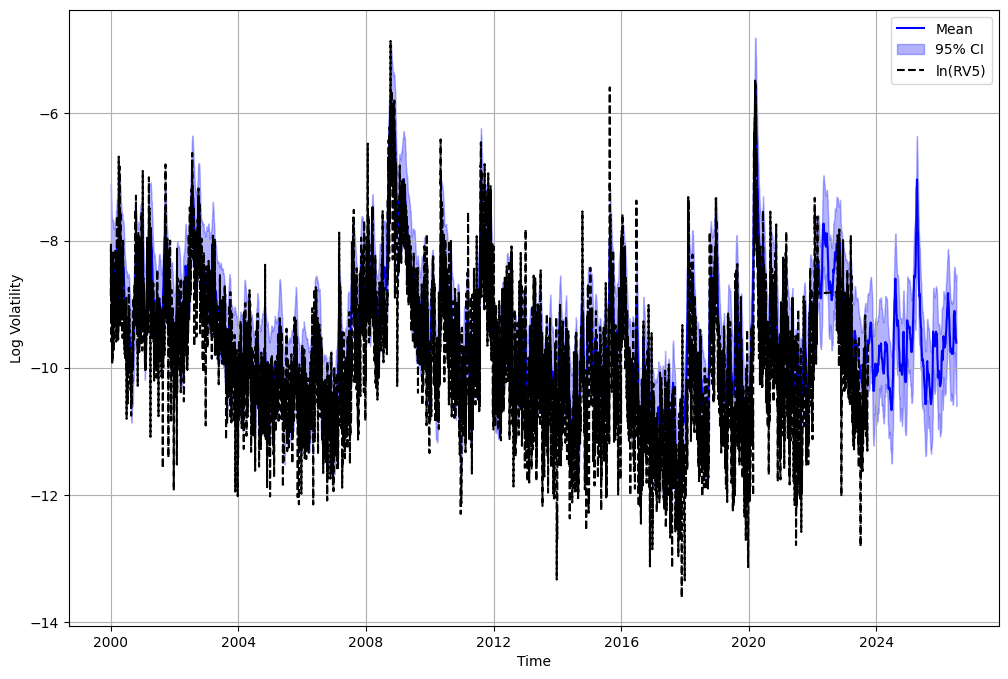

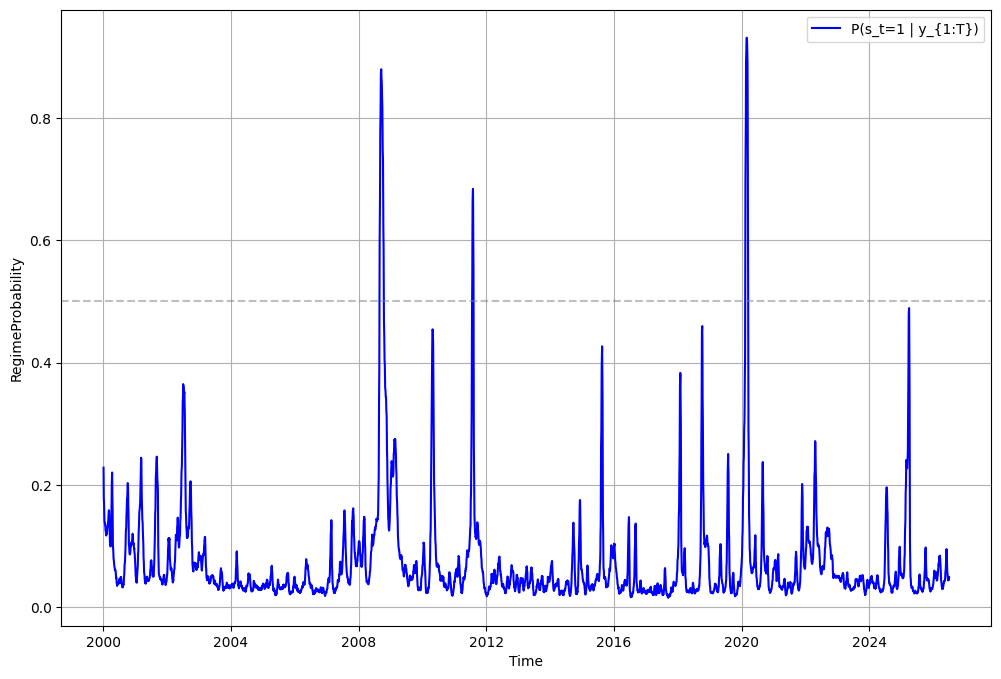

In [23]:
# -----------------------
# Smoothing h values
# -----------------------
h_values = trajectories_cluster_1[:, :, 0]     # shape (N_theta * save_factor, T+1)
means = np.sum(traj_weights_1[:, None] * h_values, axis=0)
lower, higher = weighted_credible_interval(h_values, traj_weights_1, alpha=0.05)

plt.figure(figsize=(12, 8))
plt.plot(dates, means[1:], label="Mean", color='blue')                  # Dont plot prior
plt.fill_between(dates, lower[1:], higher[1:], alpha=0.3, label="95% CI", color='blue')     # Same here
plt.plot(rv5_dates, np.log(rv5_values), label="ln(RV5)", color='black', linestyle='--')
plt.xlabel("Time")
plt.ylabel("Log Volatility")
plt.grid(True)
plt.legend()
ax = plt.gca()
ylims = ax.get_ylim()
plt.show()
plt.close()

# -----------------------
# Smoothing s values
# -----------------------
s_values = trajectories_cluster_1[:, :, 1]    # shape (N_theta * save_factor, T+1)
regime_probs = np.sum(traj_weights_1[:, None] * s_values, axis=0)

plt.figure(figsize=(12, 8))
plt.plot(dates, regime_probs[1:], label="P(s_t=1 | y_{1:T})", color='blue')                  # Dont plot prior
plt.axhline(0.5, color="grey", linestyle="--", alpha=0.5)
plt.xlabel("Time")
plt.ylabel("RegimeProbability")
plt.grid(True)
plt.legend()  
plt.show()
plt.close()

In [24]:
# Transform df parameters back to constrained space for easier interpretation
df_constrained = df.copy()
df_constrained["phi"] = df_constrained["phi"].apply(lambda x: np.tanh(x))  # Transform phi back to (-1, 1)
df_constrained["sigma^2"] = df_constrained["sigma^2"].apply(lambda x: np.exp(x))  # Transform sigma^2 back to positive values
df_constrained["P_1_1"] = df_constrained["logit_P_1_1"].apply(lambda x: 1 / (1 + np.exp(-x)))  # Transform logit_P_1_1 back to (0, 1)
df_constrained["P_1_2"] = 1 - df_constrained["P_1_1"]  # Since P_1_2 = 1 - P_1_1
df_constrained["P_2_1"] = df_constrained["logit_P_2_1"].apply(lambda x: 1 / (1 + np.exp(-x)))  # Transform logit_P_2_1 back to (0, 1)
df_constrained["P_2_2"] = 1 - df_constrained["P_2_1"]  # Since P_2_2 = 1 - P_2_1

# Drop other columns
df_constrained = df_constrained[["mu1", "delta_2", "phi", "sigma^2", "P_1_1", "P_1_2", "P_2_1", "P_2_2", "cluster"]]

In [25]:
# Print number of samples in each cluster
cluster_counts = df_constrained['cluster'].value_counts()
print("Number of samples in each cluster:")
print(cluster_counts)

Number of samples in each cluster:
cluster
0    4392
1    3608
Name: count, dtype: int64


Cluster 0 - mu1: Mean = -9.9399, 95% CI = [-10.2160, -9.6403]
Cluster 1 - mu1: Mean = -9.6946, 95% CI = [-10.0637, -9.3825]


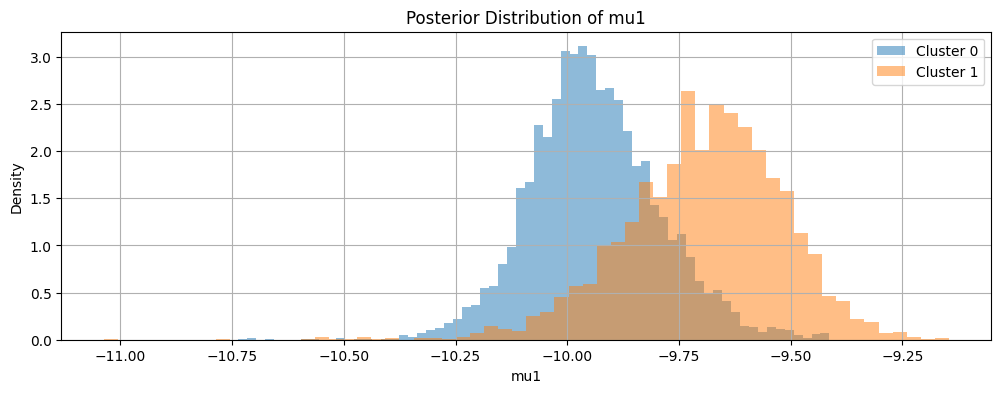

Cluster 0 - delta_2: Mean = 0.4412, 95% CI = [-0.1977, 0.8151]
Cluster 1 - delta_2: Mean = 1.5364, 95% CI = [-0.1380, 2.5111]


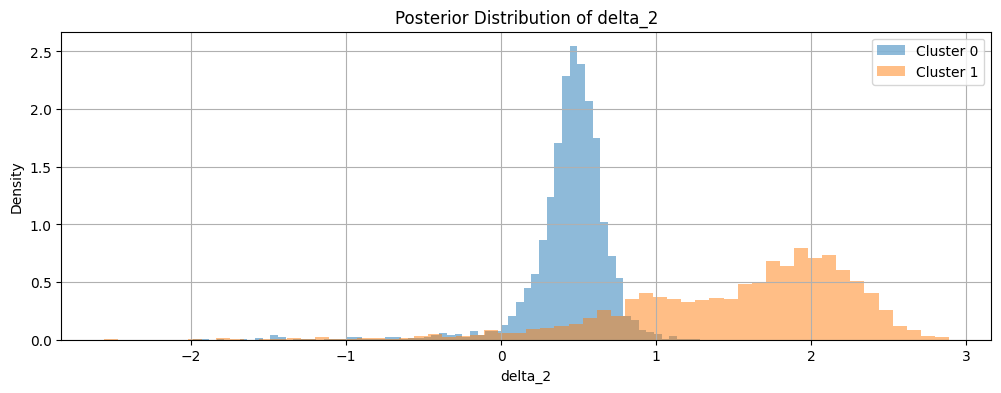

Cluster 0 - phi: Mean = 0.9574, 95% CI = [0.9382, 0.9751]
Cluster 1 - phi: Mean = 0.9753, 95% CI = [0.9664, 0.9827]


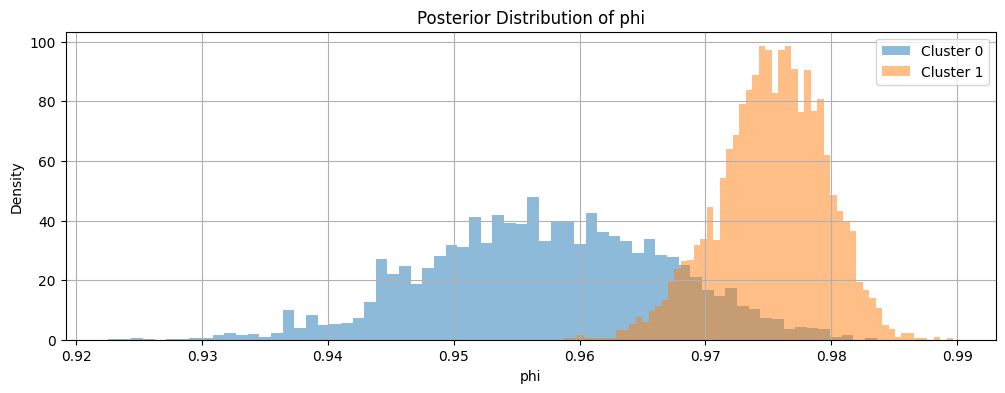

Cluster 0 - sigma^2: Mean = 0.0521, 95% CI = [0.0395, 0.0682]
Cluster 1 - sigma^2: Mean = 0.0385, 95% CI = [0.0268, 0.0507]


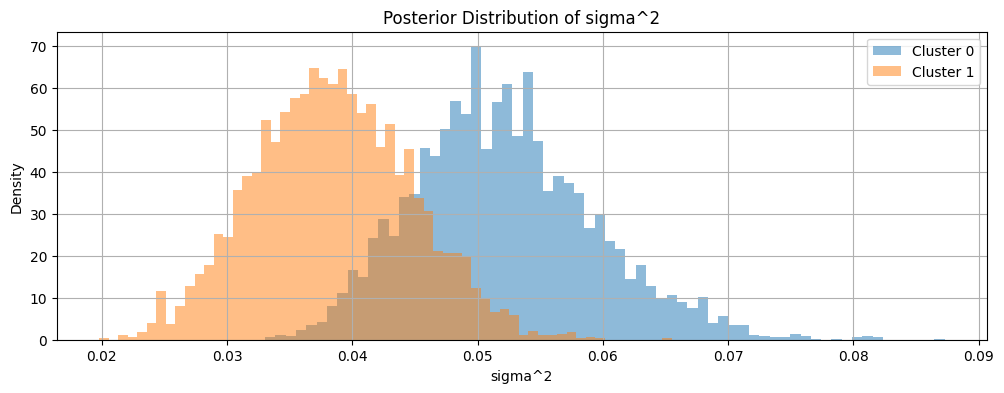

Cluster 0 - P_1_1: Mean = 0.9950, 95% CI = [0.9806, 0.9989]
Cluster 1 - P_1_1: Mean = 0.9926, 95% CI = [0.9636, 0.9992]


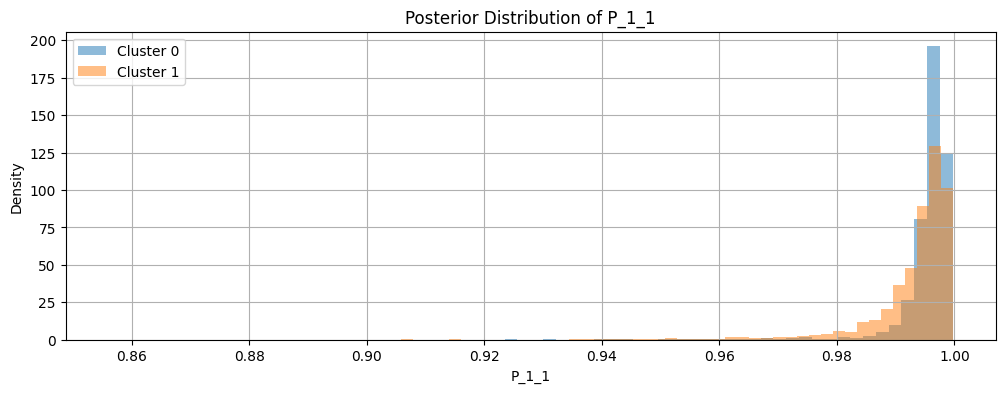

Cluster 0 - P_1_2: Mean = 0.0050, 95% CI = [0.0011, 0.0194]
Cluster 1 - P_1_2: Mean = 0.0074, 95% CI = [0.0008, 0.0364]


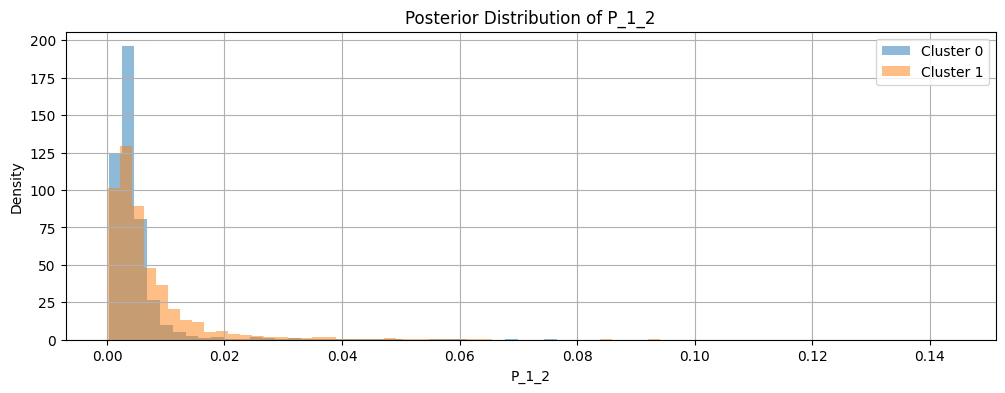

Cluster 0 - P_2_1: Mean = 0.0104, 95% CI = [0.0024, 0.0330]
Cluster 1 - P_2_1: Mean = 0.0828, 95% CI = [0.0174, 0.1826]


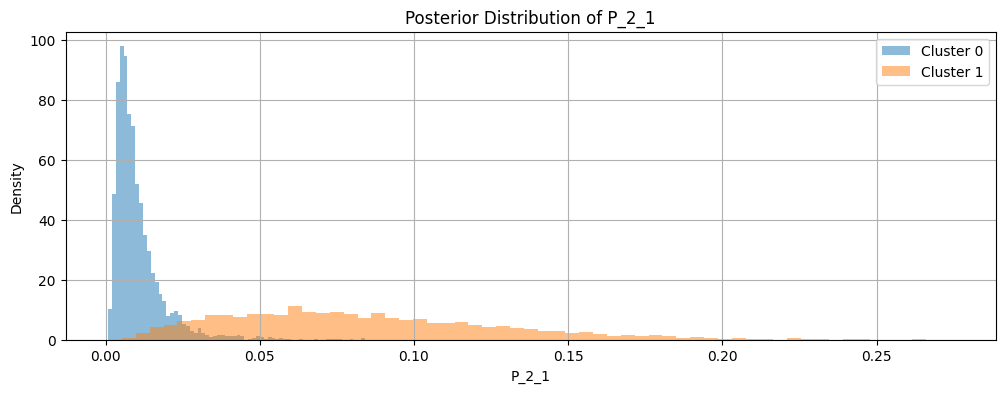

Cluster 0 - P_2_2: Mean = 0.9896, 95% CI = [0.9670, 0.9976]
Cluster 1 - P_2_2: Mean = 0.9172, 95% CI = [0.8174, 0.9826]


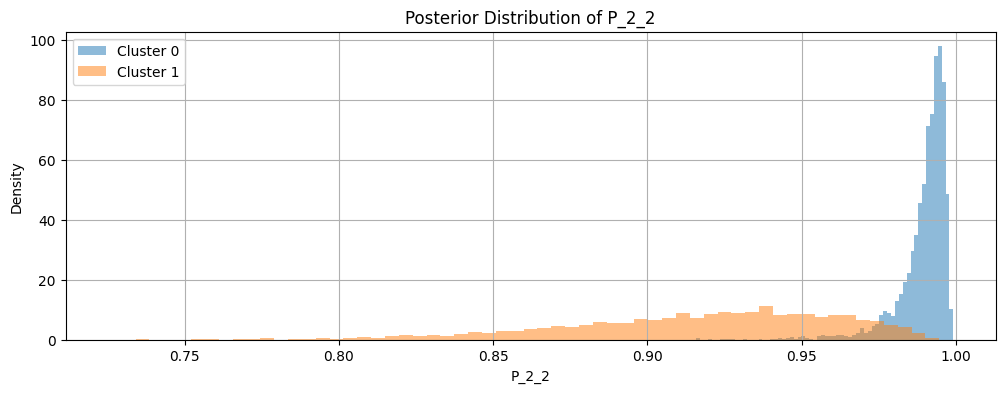

In [26]:
# Plot posterior distributions of parameters with denoted clusters
for name in df_constrained.columns:
    if name == "cluster":
        continue
    plt.figure(figsize=(12, 4))
    for cluster in [0, 1]:
        subset = df_constrained[df_constrained['cluster'] == cluster]
        mean_value = subset[name].mean()
        lo, hi = np.percentile(subset[name], [2.5, 97.5])
        print(f"Cluster {cluster} - {name}: Mean = {mean_value:.4f}, 95% CI = [{lo:.4f}, {hi:.4f}]")
        plt.hist(subset[name], bins=int(np.sqrt(len(subset))), alpha=0.5, label=f'Cluster {cluster}', density=True)
    plt.title(f'Posterior Distribution of {name}')
    plt.xlabel(name)
    plt.ylabel('Density')
    plt.legend()
    plt.grid()
    plt.show()